# Predicting Property Prices in a Specific Location Using Machine Learning

| | |
|---|---|
| **Student name** | Karan |
| **Course / Program** | Digicrome – Data Science & AI (Capstone Project 1) |
| **Project title** | Predicting Property Prices in a Specific Location Using Machine Learning |
| **Dataset** | `Digicrome_project_dataset.csv` (1,460 properties, 81 columns, Ames-type housing data) |
| **Date** | 09 October 2026 |
| **Task** | Supervised learning – Regression (target: `PropPrice`) |

### How to run (clean environment)

1. `pip install -r requirements.txt` (scikit-learn is pinned because the saved model is a pickle).
2. Put `Digicrome_project_dataset.csv` in the **same folder** as this notebook (all paths are relative).
3. *Kernel -> Restart & Run All*. The cell `%%writefile property_utils.py` regenerates the helper module.

> **Status note:** after the last recorded run, two things were edited **without re-execution**: (a) the `%%writefile property_utils.py` cell (added `regression_metrics`; `predict_property_price` now returns a float for one property) and (b) a new zero-safe metrics cross-check cell in Section 26 (it has no output yet). All other outputs shown are from the original execution. Run all cells once to refresh everything.

## 1. Introduction

**Property price prediction** means estimating the selling price of a house/plot from its characteristics – size, quality, age, neighbourhood, number of bathrooms, garage, basement and so on.

**Why is it important?** Buyers want to avoid overpaying, sellers want to avoid underpricing, and agents, banks and insurers need a fair, quick valuation. A manual valuation is slow and subjective.

**Why machine learning?** A property's price depends on *many variables at the same time* and their effects interact (a large house is worth more when its quality is high). Regression models can learn these patterns automatically from past sales and then price a new property in milliseconds.

**How this project works:** we clean the data, treat ordinal and nominal variables differently, handle missing values, explore the data (EDA), engineer new features, test scaling and PCA, train and tune several regression models, compare them with R², MAE and RMSE, and finally build a prediction function.

## 2. Problem Statement

> *Develop a machine learning regression model capable of predicting the sale price of a property based on its structural, quality, location, size, and other property-related characteristics.*

* **Input (X)** = property features (80 columns after removing nothing but the ID)
* **Output (y)** = predicted `PropPrice` (in dollars)
* **Problem type** = supervised learning
* **ML type** = regression (the target is a continuous number)
* **Target performance** (project PDF) = R² between 75 % and 85 %; above 85 % is better.

## 3. Objectives

1. Collect and clean real-estate/property data.
2. Understand and separate **ordinal** and **nominal** variables.
3. Handle missing values (`fillna()` / imputers).
4. Perform Exploratory Data Analysis (EDA).
5. Identify the variables that influence property prices.
6. Apply suitable encoding techniques.
7. Apply scaling where required.
8. Investigate PCA.
9. Perform feature engineering.
10. Build multiple machine-learning models.
11. Compare model performance.
12. Select the best-performing model.
13. Evaluate the final model.
14. Generate property price predictions.
15. Present insights and findings clearly.

## 4. Important notes about the data (read first)

* **Only one data file was supplied** (`Digicrome_project_dataset.csv`, which *contains* the target). The PDF mentions `train.csv`, `test.csv` and `sample_submission.csv`, but they were not provided. Therefore the single file is split into **train (70 %) / validation (15 %) / hold-out test (15 %)**. The hold-out test set is touched **only once**, at the very end.
* **Column names in the CSV differ slightly from the PDF** (e.g. CSV `Orientation` = PDF `LotOrientation`, CSV `SaleYr` = PDF `YrSold`, CSV `BsmtFullBath/BsmtHalfBath` = PDF `BsmtBath1/2`, CSV `KitchenUpLev` = PDF `Kitchen`). The **CSV names are used** everywhere.
* **Columns starting with `Basement…` actually describe the GARAGE** (the PDF itself says "BasementType: Garage location", "BasementCars: Size of garage in car capacity"), while the real basement columns start with `Bsmnt…`. The actual values (`Attchd`, `Detchd`, car counts) confirm this. Names are kept as given, but explained.
* **Only `PropertyID` is removed** (identifier, no predictive meaning). No other column is dropped (project note 1).
* `sample_submission.csv` is not available, so the output file follows the usual convention: `PropertyID, PropPrice`.
* `test.csv` and `data_description.txt` were also **not supplied**. Feature meanings come from the metadata table in the project PDF and could not be cross-checked against a separate data-description file.
* `submission.csv` therefore holds predictions for the **internal hold-out set**, not for an official test file (see Section 30).

## 5. Import Libraries

In [1]:
import warnings, json, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
import joblib

RANDOM_STATE = 42                      # one seed everywhere -> reproducible results
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.max_columns", 100)
os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)
RES = {}                               # we collect important numbers here (used later for the report)

def save_fig(name):
    """Save the current figure for the report and show it."""
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", bbox_inches="tight")
    plt.show()

def save_table_image(df, name, title=None, font=9, col_w=1.45, index=False, row_h=0.36):
    """Render a DataFrame as a picture (used as 'screenshot of output' in the report)."""
    d = df.reset_index() if index else df.copy()
    def _fmt(v):
        if isinstance(v, (float, np.floating)):
            return f"{v:,.0f}" if abs(v) >= 1000 else f"{v:.4g}" if abs(v) < 10 else f"{v:,.1f}"
        return str(v)
    d = d.map(_fmt)
    fig_w = max(6, col_w * len(d.columns))
    fig, ax = plt.subplots(figsize=(fig_w, row_h * (len(d) + 2) + (0.5 if title else 0.1)))
    ax.axis("off")
    tbl = ax.table(cellText=d.values, colLabels=d.columns, cellLoc="center", loc="center")
    tbl.auto_set_font_size(False); tbl.set_fontsize(font); tbl.scale(1, 1.35)
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if r == 0:
            cell.set_facecolor("#1F3A5F"); cell.set_text_props(color="white", weight="bold")
        elif r % 2 == 0:
            cell.set_facecolor("#F2F5FA")
    if title:
        ax.set_title(title, fontsize=font + 3, weight="bold", pad=8)
    fig.savefig(f"figures/{name}.png", bbox_inches="tight", dpi=170)
    plt.close(fig)

## 5b. Project helper module (`property_utils.py`)

All **cleaning rules, ordinal/nominal definitions, feature engineering and pipeline builders** live in one small Python file. This has two benefits:

1. The saved model can be re-loaded in *any* script/notebook and still work on raw property data.
2. Every step is row-wise or fitted inside a `Pipeline`, which protects us from **data leakage**.

Sections 6-12 explain each part in detail (ordinal/nominal lists, encoding, `fillna()` cleaning, feature engineering).

In [2]:
%%writefile property_utils.py
"""Helper code for the Property Price Prediction capstone project.
All functions here work ROW-BY-ROW (or learn only from training data inside a
Pipeline), so they cannot leak information from the validation/test data."""
import numpy as np
import pandas as pd
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "PropPrice"
ID_COL = "PropertyID"

RAW_FEATURES = ['PropertyID', 'PropertyClass', 'PropertyZone', 'PropertyFrontage', 'PropertySize', 'Street', 'Alley', 'PropertyShape', 'Elevation', 'Amenities', 'Orientation', 'Grade', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'PropertyStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Roof1Material', 'Roof2Material', 'ExteriorCladdingType', 'ExteriorCladdingArea', 'ExterQual', 'ExterCond', 'PropertyFooting', 'BsmntFinish', 'BsmntMaintenance', 'BsmntVisibility', 'BsmntFinRat1', 'BsmntFinSty1', 'BsmntFinQual1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmntSqFtage', 'Heating', 'HeatingEfficiency', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'Bath1', 'Bath2', 'BedroomUpLev', 'KitchenUpLev', 'KitchenQual', 'CntRmsUpLev', 'Functional', 'CntFireplaces', 'QualFireplace', 'BasementType', 'BasementYrBlt', 'BasementFinish', 'BasementCars', 'BasementSqFootage', 'BasementQual', 'BasementCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC', 'BoundaryFeatures', 'AddFeatures', 'AddVal', 'SaleMon', 'SaleYr', 'SaleType', 'SaleCondn']

# ------------------------------------------------------------------
# 1. ORDINAL columns  ->  explicit order (lowest -> highest)
# ------------------------------------------------------------------
QUAL = ["None", "Po", "Fa", "TA", "Gd", "Ex"]          # Poor < Fair < Typical < Good < Excellent
ORDINAL_ORDER = {
    "ExterQual": QUAL, "ExterCond": QUAL, "HeatingEfficiency": QUAL, "KitchenQual": QUAL,
    "QualFireplace": QUAL, "PoolQC": QUAL,
    "BsmntFinish": QUAL, "BsmntMaintenance": QUAL,           # basement height / condition
    "BasementQual": QUAL, "BasementCond": QUAL,              # (these 'Basement*' columns hold GARAGE data)
    "BsmntVisibility": ["None", "No", "Mn", "Av", "Gd"],     # basement exposure
    "BsmntFinRat1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmntFinQual1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BasementFinish": ["None", "Unf", "RFn", "Fin"],         # garage interior finish
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "PavedDrive": ["N", "P", "Y"],
    "PropertyShape": ["IR3", "IR2", "IR1", "Reg"],
    "Grade": ["Sev", "Mod", "Gtl"],                           # land slope
    "Amenities": ["ELO", "NoSeWa", "NoSewr", "AllPub"],      # utilities
    "Street": ["Grvl", "Pave"],
    "CentralAir": ["N", "Y"],
    "BoundaryFeatures": ["None", "MnWw", "GdWo", "MnPrv", "GdPrv"],   # fence quality / privacy
}
ORDINAL_COLS = list(ORDINAL_ORDER)

# ------------------------------------------------------------------
# 2. NOMINAL columns  ->  One-Hot Encoding (no natural order)
# ------------------------------------------------------------------
NOMINAL_COLS = [
    "PropertyClass", "PropertyZone", "Alley", "Elevation", "Orientation", "Neighborhood",
    "Condition1", "Condition2", "BldgType", "PropertyStyle", "RoofStyle", "RoofMatl",
    "Roof1Material", "Roof2Material", "ExteriorCladdingType", "PropertyFooting", "Heating",
    "Electrical", "BasementType", "AddFeatures", "SaleType", "SaleCondn", "SaleMon",
]
# PropertyClass is a numeric CODE (20, 60, ...) and SaleMon is a month number -> treated as categories.

# ------------------------------------------------------------------
# 3. Cleaning + feature engineering (row-wise, leakage-free)
# ------------------------------------------------------------------
def clean_data(df):
    """Convert 'structural absence' (e.g. no pool, no garage) from NaN to an explicit 'None'
    category using fillna(). Real unknown values stay NaN and are imputed later inside the
    Pipeline (fitted on training data only)."""
    df = df.copy()
    df = df.drop(columns=[c for c in [ID_COL, TARGET] if c in df.columns])
    df = df.replace("NA", np.nan)
    for c in RAW_FEATURES:                       # allow partial inputs (missing fields become NaN)
        if c not in df.columns:
            df[c] = np.nan

    # --- basement columns: NaN + zero basement area  ->  'None' ---
    no_bsmt = df["BsmntSqFtage"].fillna(0) == 0
    for c in ["BsmntFinish", "BsmntMaintenance", "BsmntVisibility", "BsmntFinRat1", "BsmntFinQual1"]:
        df[c] = df[c].where(~(no_bsmt & df[c].isna()), "None")
    # --- 'Basement*' columns actually describe the GARAGE: NaN + zero cars -> 'None' ---
    no_garage = df["BasementCars"].fillna(0) == 0
    for c in ["BasementType", "BasementFinish", "BasementQual", "BasementCond"]:
        df[c] = df[c].where(~(no_garage & df[c].isna()), "None")
    df["BasementYrBlt"] = df["BasementYrBlt"].fillna(df["YearBuilt"])     # no garage -> use house year
    # --- fireplace / pool / alley / fence / misc: NaN really means 'feature not present' ---
    df["QualFireplace"] = df["QualFireplace"].where(~((df["CntFireplaces"] == 0) & df["QualFireplace"].isna()), "None")
    df["PoolQC"] = df["PoolQC"].where(~((df["PoolArea"] == 0) & df["PoolQC"].isna()), "None")
    for c in ["Alley", "BoundaryFeatures", "AddFeatures"]:
        df[c] = df[c].fillna("None")
    # --- masonry veneer: pandas reads the category 'None' as NaN; if the area is known it is 'None' ---
    df["ExteriorCladdingType"] = df["ExteriorCladdingType"].where(
        ~(df["ExteriorCladdingType"].isna() & df["ExteriorCladdingArea"].notna()), "None")
    # --- codes that are really categories ---
    df["PropertyClass"] = df["PropertyClass"].astype(str)
    df["SaleMon"] = df["SaleMon"].astype(str)
    return df


def add_features(df):
    """Domain-knowledge features (each uses only the same row)."""
    df = df.copy()
    df["TotalSF"] = df["BsmntSqFtage"] + df["1stFlrSF"] + df["2ndFlrSF"]
    df["TotalBathrooms"] = df["Bath1"] + 0.5 * df["Bath2"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
    df["TotalPorchSF"] = df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"] + df["WoodDeckSF"]
    df["HouseAge"] = (df["SaleYr"] - df["YearBuilt"]).clip(lower=0)
    df["RemodelAge"] = (df["SaleYr"] - df["YearRemodAdd"]).clip(lower=0)
    df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)
    df["HasGarage"] = (df["BasementCars"] > 0).astype(int)
    df["HasBasement"] = (df["BsmntSqFtage"] > 0).astype(int)
    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)
    df["HasFireplace"] = (df["CntFireplaces"] > 0).astype(int)
    df["QualxLivArea"] = df["OverallQual"] * df["GrLivArea"]
    return df


def prepare_df(df, engineer=True):
    out = clean_data(df)
    return add_features(out) if engineer else out


# ------------------------------------------------------------------
# 4. Small custom transformer: log1p on skewed numeric columns (skew learnt on TRAIN only)
# ------------------------------------------------------------------
class SkewFixer(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.75):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        sk = np.apply_along_axis(lambda c: skew(c), 0, X)
        self.cols_ = np.where((np.abs(sk) > self.threshold) & (X.min(axis=0) >= 0))[0]
        return self

    def transform(self, X):
        X = np.array(X, dtype=float)
        X[:, self.cols_] = np.log1p(X[:, self.cols_])
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


# ------------------------------------------------------------------
# 5. Pipeline builders
# ------------------------------------------------------------------
def build_encoder(scaled=True):
    """ColumnTransformer: numeric / ordinal / nominal handled separately.
    scaled=True  -> for linear models & PCA (log-skew fix + StandardScaler)
    scaled=False -> for tree models (scaling is unnecessary)"""
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scaled:
        num_steps += [("skew", SkewFixer()), ("scale", StandardScaler())]
    numeric = Pipeline(num_steps)

    ordinal_steps = [
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OrdinalEncoder(categories=[ORDINAL_ORDER[c] for c in ORDINAL_COLS],
                                  handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    if scaled:
        ordinal_steps.append(("scale", StandardScaler()))
    ordinal = Pipeline(ordinal_steps)

    nominal = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric, make_column_selector(dtype_include=np.number)),
        ("ord", ordinal, ORDINAL_COLS),
        ("nom", nominal, NOMINAL_COLS),
    ], verbose_feature_names_out=False)


def make_model(estimator, scaled=True, engineer=True, pca=None, log_target=True):
    steps = [
        ("prep", FunctionTransformer(prepare_df, kw_args={"engineer": engineer})),
        ("encode", build_encoder(scaled)),
    ]
    if pca is not None:
        steps.append(("pca", PCA(n_components=pca, random_state=RANDOM_STATE)))
    steps.append(("model", estimator))
    pipe = Pipeline(steps)
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return TransformedTargetRegressor(regressor=pipe)   # identity transform


def predict_property_price(model, property_data):
    """property_data: dict (one property) or DataFrame (many properties).
    Missing fields are allowed (NaN) and handled by the pipeline.
    Returns a float for one property (dict) and a NumPy array for a DataFrame."""
    if isinstance(property_data, dict):
        return float(model.predict(pd.DataFrame([property_data]))[0])
    return model.predict(property_data.copy())


# ------------------------------------------------------------------
# 6. Evaluation metrics (safe when a true price is 0)
# ------------------------------------------------------------------
def regression_metrics(y_true, y_pred, margins=(10, 20)):
    """R2, MAE, RMSE and percentage-error metrics.

    A percentage error divides by the true price, which is undefined when the true
    price is 0. Such rows are EXCLUDED from MAPE, median abs % error and the
    'within X %' shares (and counted in 'zero-target rows excluded'), so no
    division-by-zero or inf ever appears. R2, MAE and RMSE use all rows.
    (The PropPrice column has no zero values, so nothing is excluded in this project.)"""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    out = {"R2": r2_score(y_true, y_pred),
           "MAE": mean_absolute_error(y_true, y_pred),
           "RMSE": root_mean_squared_error(y_true, y_pred)}
    ok = y_true != 0
    ape = np.abs((y_true[ok] - y_pred[ok]) / y_true[ok]) * 100 if ok.any() else np.array([])
    out["MAPE %"] = float(ape.mean()) if ape.size else float("nan")
    out["Median abs % error"] = float(np.median(ape)) if ape.size else float("nan")
    for m in margins:
        out[f"Within {m}% of real price"] = float((ape <= m).mean() * 100) if ape.size else float("nan")
    out["Zero-target rows excluded"] = int((~ok).sum())
    return out

Overwriting property_utils.py


In [3]:
from property_utils import *
print("Helper module loaded.  Ordinal columns:", len(ORDINAL_COLS), "| Nominal columns:", len(NOMINAL_COLS))

Helper module loaded.  Ordinal columns: 22 | Nominal columns: 23


## 6. Load Data

In [4]:
DATA_PATH = "Digicrome_project_dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape (rows, columns):", df.shape)
print("Target variable              :", TARGET)
print("ID column                    :", ID_COL)
print("\nColumn names:")
print(list(df.columns))
print("\nData types:")
print(df.dtypes.value_counts())

Dataset shape (rows, columns): (1460, 81)
Target variable              : PropPrice
ID column                    : PropertyID

Column names:
['PropertyID', 'PropertyClass', 'PropertyZone', 'PropertyFrontage', 'PropertySize', 'Street', 'Alley', 'PropertyShape', 'Elevation', 'Amenities', 'Orientation', 'Grade', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'PropertyStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Roof1Material', 'Roof2Material', 'ExteriorCladdingType', 'ExteriorCladdingArea', 'ExterQual', 'ExterCond', 'PropertyFooting', 'BsmntFinish', 'BsmntMaintenance', 'BsmntVisibility', 'BsmntFinRat1', 'BsmntFinSty1', 'BsmntFinQual1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmntSqFtage', 'Heating', 'HeatingEfficiency', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'Bath1', 'Bath2', 'BedroomUpLev', 'KitchenUpLev', 'KitchenQual', 'CntRmsUpLev', 'Functional', 'CntFireplaces', 'Qua

In [5]:
display(df.head())          # first rows
display(df.tail(3))         # last rows
save_table_image(df[["PropertyID","PropertyClass","PropertyZone","PropertySize","Neighborhood","OverallQual",
                     "YearBuilt","GrLivArea","SaleYr","PropPrice"]].head(8),
                 "shot_01_dataset_head", "Dataset preview (first 8 rows, 10 of 81 columns)")

,PropertyID,PropertyClass,PropertyZone,PropertyFrontage,PropertySize,Street,Alley,PropertyShape,Elevation,Amenities,Orientation,Grade,Neighborhood,Condition1,Condition2,BldgType,PropertyStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Roof1Material,Roof2Material,ExteriorCladdingType,ExteriorCladdingArea,ExterQual,ExterCond,PropertyFooting,BsmntFinish,BsmntMaintenance,BsmntVisibility,BsmntFinRat1,BsmntFinSty1,BsmntFinQual1,BsmtFinSF2,BsmtUnfSF,BsmntSqFtage,Heating,HeatingEfficiency,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,Bath1,Bath2,BedroomUpLev,KitchenUpLev,KitchenQual,CntRmsUpLev,Functional,CntFireplaces,QualFireplace,BasementType,BasementYrBlt,BasementFinish,BasementCars,BasementSqFootage,BasementQual,BasementCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,BoundaryFeatures,AddFeatures,AddVal,SaleMon,SaleYr,SaleType,SaleCondn,PropPrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,PropertyID,PropertyClass,PropertyZone,PropertyFrontage,PropertySize,Street,Alley,PropertyShape,Elevation,Amenities,Orientation,Grade,Neighborhood,Condition1,Condition2,BldgType,PropertyStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Roof1Material,Roof2Material,ExteriorCladdingType,ExteriorCladdingArea,ExterQual,ExterCond,PropertyFooting,BsmntFinish,BsmntMaintenance,BsmntVisibility,BsmntFinRat1,BsmntFinSty1,BsmntFinQual1,BsmtFinSF2,BsmtUnfSF,BsmntSqFtage,Heating,HeatingEfficiency,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,Bath1,Bath2,BedroomUpLev,KitchenUpLev,KitchenQual,CntRmsUpLev,Functional,CntFireplaces,QualFireplace,BasementType,BasementYrBlt,BasementFinish,BasementCars,BasementSqFootage,BasementQual,BasementCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,BoundaryFeatures,AddFeatures,AddVal,SaleMon,SaleYr,SaleType,SaleCondn,PropPrice
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,9,1941,2006,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,Ex,Gd,Stone,TA,Gd,No,GLQ,275,Unf,0,877,1152,GasA,Ex,Y,SBrkr,1188,1152,0,2340,0,0,2,0,4,1,Gd,9,Typ,2,Gd,Attchd,1941.0,RFn,1,252,TA,TA,Y,0,60,0,0,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,6,1950,1996,Hip,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,TA,TA,Mn,GLQ,49,Rec,1029,0,1078,GasA,Gd,Y,FuseA,1078,0,0,1078,1,0,1,0,2,1,Gd,5,Typ,0,NaN,Attchd,1950.0,Unf,1,240,TA,TA,Y,366,0,112,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,Norm,1Fam,1Story,5,6,1965,1965,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,CBlock,TA,TA,No,BLQ,830,LwQ,290,136,1256,GasA,Gd,Y,SBrkr,1256,0,0,1256,1,0,1,1,3,1,TA,6,Typ,0,NaN,Attchd,1965.0,Fin,1,276,TA,TA,Y,736,68,0,0,0,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [6]:
# --- Identify the type of every column using the metadata (ordinal / nominal / numeric) ---
ordinal_cols = ORDINAL_COLS
nominal_cols = NOMINAL_COLS
numeric_cols = [c for c in df.columns if c not in ordinal_cols + nominal_cols + [TARGET, ID_COL]]

print(f"Target     : {TARGET}")
print(f"ID column  : {ID_COL}")
print(f"Numeric    : {len(numeric_cols)} columns")
print(f"Ordinal    : {len(ordinal_cols)} columns")
print(f"Nominal    : {len(nominal_cols)} columns")
print("Total      :", 2 + len(numeric_cols) + len(ordinal_cols) + len(nominal_cols), "(= all 81 columns)")
print("\nDuplicate rows       :", df.duplicated().sum())
print("Duplicate PropertyID :", df[ID_COL].duplicated().sum())
print("\nNo separate test.csv was provided -> we create our own train/validation/hold-out test split later.")

Target     : PropPrice
ID column  : PropertyID
Numeric    : 34 columns
Ordinal    : 22 columns
Nominal    : 23 columns
Total      : 81 (= all 81 columns)

Duplicate rows       : 0
Duplicate PropertyID : 0

No separate test.csv was provided -> we create our own train/validation/hold-out test split later.


## 7. Initial Data Understanding

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   PropertyID            1460 non-null   int64  
 1   PropertyClass         1460 non-null   int64  
 2   PropertyZone          1460 non-null   str    
 3   PropertyFrontage      1201 non-null   float64
 4   PropertySize          1460 non-null   int64  
 5   Street                1460 non-null   str    
 6   Alley                 91 non-null     str    
 7   PropertyShape         1460 non-null   str    
 8   Elevation             1460 non-null   str    
 9   Amenities             1460 non-null   str    
 10  Orientation           1460 non-null   str    
 11  Grade                 1460 non-null   str    
 12  Neighborhood          1460 non-null   str    
 13  Condition1            1460 non-null   str    
 14  Condition2            1460 non-null   str    
 15  BldgType              1460 non-n

In [8]:
display(df.describe().T.round(2))
print("Duplicated rows:", df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
PropertyID,1460.0,730.50,421.61,1.0,365.75,730.5,1095.25,1460.0
PropertyClass,1460.0,56.90,42.30,20.0,20.00,50.0,70.00,190.0
PropertyFrontage,1201.0,70.05,24.28,21.0,59.00,69.0,80.00,313.0
PropertySize,1460.0,10516.83,9981.26,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.10,1.38,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.58,1.11,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.27,30.20,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.87,20.65,1950.0,1967.00,1994.0,2004.00,2010.0
ExteriorCladdingArea,1452.0,103.69,181.07,0.0,0.00,0.0,166.00,1600.0
BsmntFinSty1,1460.0,443.64,456.10,0.0,0.00,383.5,712.25,5644.0


Duplicated rows: 0


In [9]:
# --- Suspicious values / inconsistencies ---
checks = {
    "Negative numeric values": int((df.select_dtypes("number") < 0).sum().sum()),
    "YearBuilt > SaleYr": int((df.YearBuilt > df.SaleYr).sum()),
    "YearRemodAdd > SaleYr (remodel after sale?)": int((df.YearRemodAdd > df.SaleYr).sum()),
    "YearRemodAdd < YearBuilt": int((df.YearRemodAdd < df.YearBuilt).sum()),
    "GrLivArea != 1stFlr + 2ndFlr + LowQual": int((df["1stFlrSF"] + df["2ndFlrSF"] + df.LowQualFinSF != df.GrLivArea).sum()),
    "Basement parts != total basement area": int((df.BsmntFinSty1 + df.BsmtFinSF2 + df.BsmtUnfSF != df.BsmntSqFtage).sum()),
    "Garage built before house (BasementYrBlt < YearBuilt)": int((df.BasementYrBlt < df.YearBuilt).sum()),
    "Frontage > 300 ft": int((df.PropertyFrontage > 300).sum()),
    "GrLivArea > 4000 sq ft": int((df.GrLivArea > 4000).sum()),
}
display(pd.Series(checks, name="count").to_frame())
display(df[df.YearRemodAdd > df.SaleYr][["PropertyID","YearBuilt","YearRemodAdd","SaleYr"]])

,count
Negative numeric values,0
YearBuilt > SaleYr,0
YearRemodAdd > SaleYr (remodel after sale?),1
YearRemodAdd < YearBuilt,0
GrLivArea != 1stFlr + 2ndFlr + LowQual,0
Basement parts != total basement area,0
Garage built before house (BasementYrBlt < YearBuilt),9
Frontage > 300 ft,2
GrLivArea > 4000 sq ft,4


,PropertyID,YearBuilt,YearRemodAdd,SaleYr
523,524,2007,2008,2007


**Findings:** no negative values, no duplicates, and the area columns add up exactly (GrLivArea = 1st + 2nd floor + low-quality; basement parts = total basement). Small inconsistencies: **one** property (ID 524) has a remodel year (2008) after its sale year (2007), 9 garages were built before the house itself (plausible - a garage can pre-date a rebuilt house), 2 frontage values are above 300 ft, and 4 houses exceed 4,000 sq ft. None is an impossible value, so nothing is deleted at this stage; `RemodelAge`/`HouseAge` are clipped at 0 later.

In [10]:
# --- Structured data-quality summary ---
def role_of(c):
    if c == TARGET: return "Target"
    if c == ID_COL: return "ID (removed)"
    if c in ordinal_cols: return "Ordinal"
    if c in nominal_cols: return "Nominal"
    return "Numeric"

dq = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).values,
    "Missing": df.isnull().sum().values,
    "Missing %": (df.isnull().mean() * 100).round(2).values,
    "Unique": df.nunique().values,
    "Role": [role_of(c) for c in df.columns],
})
dq["Numerical / Categorical"] = np.where(dq.Role.isin(["Ordinal", "Nominal"]), "Categorical", "Numerical")
dq.to_csv("tables/data_quality_summary.csv", index=False)
display(dq)
RES["shape"] = list(df.shape)
RES["role_counts"] = dq.Role.value_counts().to_dict()

,Column,Data type,Missing,Missing %,Unique,Role,Numerical / Categorical
0,PropertyID,int64,0,0.00,1460,ID (removed),Numerical
1,PropertyClass,int64,0,0.00,15,Nominal,Categorical
2,PropertyZone,str,0,0.00,5,Nominal,Categorical
3,PropertyFrontage,float64,259,17.74,110,Numeric,Numerical
4,PropertySize,int64,0,0.00,1073,Numeric,Numerical
...,...,...,...,...,...,...,...
76,SaleMon,int64,0,0.00,12,Nominal,Categorical
77,SaleYr,int64,0,0.00,5,Numeric,Numerical
78,SaleType,str,0,0.00,9,Nominal,Categorical
79,SaleCondn,str,0,0.00,6,Nominal,Categorical


## 8. Target Variable Analysis – `PropPrice`

,PropPrice
min,34900.000
max,755000.000
mean,180921.196
median,163000.000
std,79442.503
skewness,1.883
kurtosis,6.536
skewness after log1p,0.121


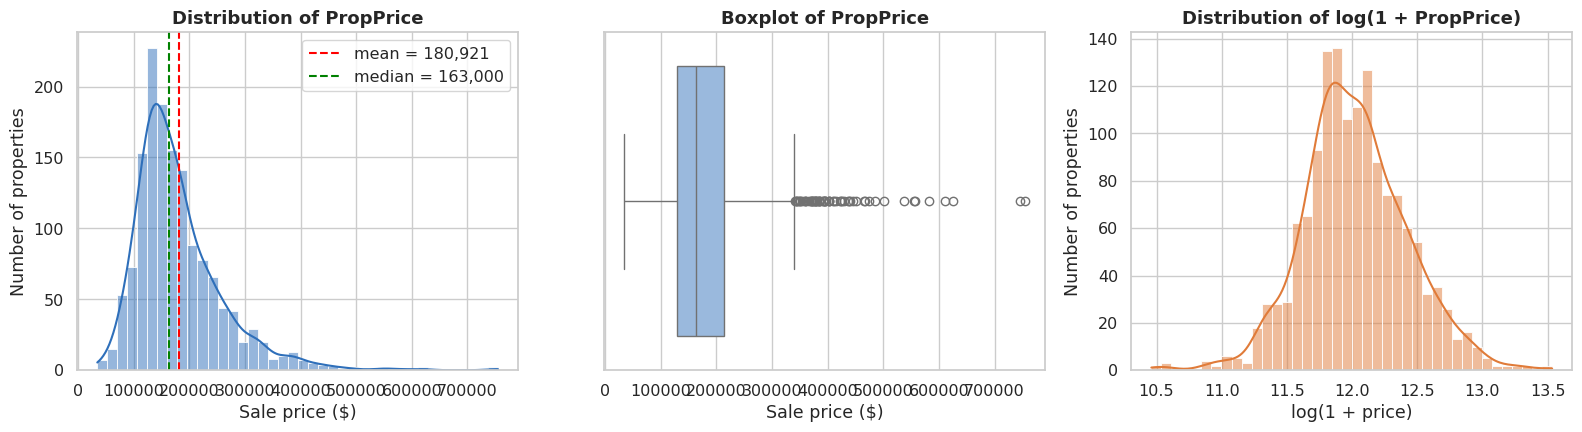

In [11]:
t = df[TARGET]
tstats = pd.Series({"min": t.min(), "max": t.max(), "mean": t.mean(), "median": t.median(),
                    "std": t.std(), "skewness": t.skew(), "kurtosis": t.kurt(),
                    "skewness after log1p": np.log1p(t).skew()}).round(3)
display(tstats.to_frame("PropPrice"))
RES["target_stats"] = tstats.to_dict()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(t, bins=40, kde=True, color="#2E6FBA", ax=ax[0])
ax[0].axvline(t.mean(), color="red", ls="--", label=f"mean = {t.mean():,.0f}")
ax[0].axvline(t.median(), color="green", ls="--", label=f"median = {t.median():,.0f}")
ax[0].set_title("Distribution of PropPrice"); ax[0].set_xlabel("Sale price ($)"); ax[0].set_ylabel("Number of properties"); ax[0].legend()
sns.boxplot(x=t, color="#8FB8E8", ax=ax[1])
ax[1].set_title("Boxplot of PropPrice"); ax[1].set_xlabel("Sale price ($)")
sns.histplot(np.log1p(t), bins=40, kde=True, color="#E07B39", ax=ax[2])
ax[2].set_title("Distribution of log(1 + PropPrice)"); ax[2].set_xlabel("log(1 + price)"); ax[2].set_ylabel("Number of properties")
save_fig("01_target_distribution")

**Insight:** `PropPrice` ranges from $34,900 to $755,000 with mean $180,921 and median $163,000. Mean > median and skewness = 1.88 show a clear **right skew** (a few very expensive houses). After `log(1 + price)` the skewness falls to 0.12, almost symmetric. Because linear models assume roughly symmetric errors, a log target is promising - but it is tested objectively in Section 18.3 instead of being assumed.

## 9. Missing Value Analysis

Not every `NaN` means "data is missing". In this dataset (see the metadata sheet) most `NaN`s mean **"the property does not have this feature"** (no alley, no pool, no fireplace, no garage, no basement). Filling these with zero or the median would be **wrong**. We therefore separate:

| Kind of missingness | Example | Treatment |
|---|---|---|
| **Genuine absence** | `PoolQC` is NaN when `PoolArea = 0` | explicit category **`"None"`** using `fillna()` |
| **Unknown measurement** | `PropertyFrontage` | **median** imputation (+ missing-indicator column) |
| **Categorical unknown** | `Electrical` (1 row) | **most-frequent (mode)** imputation |
| **Numerical unknown** | `ExteriorCladdingArea` (8 rows) | **median** imputation |

Absence rules use only the *same row* (e.g. "no basement area -> no basement quality") so they cannot leak information. True unknowns are imputed **inside the Pipeline, fitted on training data only**.

,Missing count,Missing %,Likely reason,Treatment
PoolQC,1453,99.52,No pool (PoolArea = 0) - genuine absence,fillna('None')
AddFeatures,1406,96.30,No miscellaneous feature - genuine absence,fillna('None')
Alley,1369,93.77,No alley access - genuine absence,fillna('None')
BoundaryFeatures,1179,80.75,No fence - genuine absence,fillna('None')
ExteriorCladdingType,872,59.73,Text 'None' (no masonry veneer) was read as Na...,'None' where area known; remaining 8 -> mode
QualFireplace,690,47.26,No fireplace (CntFireplaces = 0) - genuine abs...,'None' where CntFireplaces = 0
PropertyFrontage,259,17.74,Frontage was not measured/recorded - unknown,median + missing indicator (Pipeline)
BasementType,81,5.55,No garage - genuine absence,'None' where BasementCars = 0
BasementYrBlt,81,5.55,"No garage, so no garage year",fillna(YearBuilt)
BasementFinish,81,5.55,No garage - genuine absence,'None' where BasementCars = 0


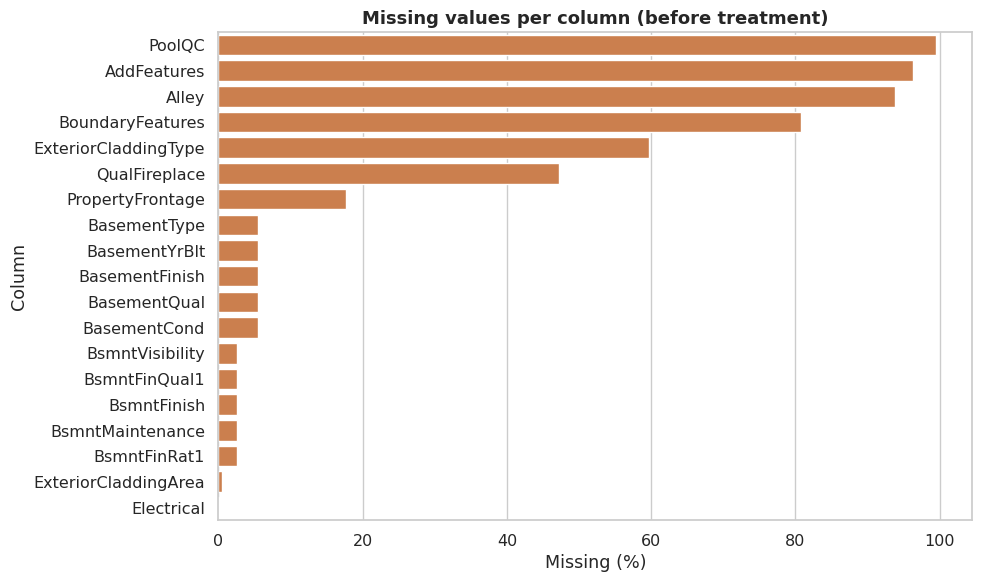

In [12]:
miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)

reason = {
 "PoolQC": "No pool (PoolArea = 0) - genuine absence",
 "AddFeatures": "No miscellaneous feature - genuine absence",
 "Alley": "No alley access - genuine absence",
 "ExteriorCladdingType": "Text 'None' (no masonry veneer) was read as NaN by pandas; only 8 rows are truly unknown",
 "BoundaryFeatures": "No fence - genuine absence",
 "QualFireplace": "No fireplace (CntFireplaces = 0) - genuine absence",
 "PropertyFrontage": "Frontage was not measured/recorded - unknown",
 "BasementType": "No garage - genuine absence", "BasementFinish": "No garage - genuine absence",
 "BasementQual": "No garage - genuine absence", "BasementCond": "No garage - genuine absence",
 "BasementYrBlt": "No garage, so no garage year",
 "BsmntFinish": "No basement - genuine absence", "BsmntMaintenance": "No basement - genuine absence",
 "BsmntVisibility": "No basement (37 rows) + 1 unknown", "BsmntFinRat1": "No basement - genuine absence",
 "BsmntFinQual1": "No basement (37 rows) + 1 unknown",
 "ExteriorCladdingArea": "Unknown area (8 rows)", "Electrical": "Unknown (1 row)",
}
treatment = {
 "PoolQC": "fillna('None')", "AddFeatures": "fillna('None')", "Alley": "fillna('None')",
 "ExteriorCladdingType": "'None' where area known; remaining 8 -> mode",
 "BoundaryFeatures": "fillna('None')", "QualFireplace": "'None' where CntFireplaces = 0",
 "PropertyFrontage": "median + missing indicator (Pipeline)",
 "BasementType": "'None' where BasementCars = 0", "BasementFinish": "'None' where BasementCars = 0",
 "BasementQual": "'None' where BasementCars = 0", "BasementCond": "'None' where BasementCars = 0",
 "BasementYrBlt": "fillna(YearBuilt)",
 "BsmntFinish": "'None' where basement area = 0", "BsmntMaintenance": "'None' where basement area = 0",
 "BsmntVisibility": "'None' if no basement; 1 unknown -> mode", "BsmntFinRat1": "'None' where basement area = 0",
 "BsmntFinQual1": "'None' if no basement; 1 unknown -> mode",
 "ExteriorCladdingArea": "median (Pipeline)", "Electrical": "mode (Pipeline)",
}
missing_report = pd.DataFrame({
    "Missing count": miss, "Missing %": (miss / len(df) * 100).round(2),
    "Likely reason": [reason[c] for c in miss.index], "Treatment": [treatment[c] for c in miss.index]})
display(missing_report)
missing_report.to_csv("tables/missing_value_report.csv")
save_table_image(missing_report.reset_index().rename(columns={"index": "Column"})[["Column","Missing count","Missing %","Treatment"]].head(14),
                 "shot_02_missing_values", "Missing-value report (top 14 columns)", col_w=2.6, font=8)

plt.figure(figsize=(10, 6))
sns.barplot(x=missing_report["Missing %"], y=missing_report.index, color="#E07B39")
plt.title("Missing values per column (before treatment)"); plt.xlabel("Missing (%)"); plt.ylabel("Column")
save_fig("02_missing_values")
RES["missing_cols"] = int(len(miss)); RES["missing_cells"] = int(miss.sum())

In [13]:
# --- Demonstration of the cleaning step (fillna-based) ---
cleaned = clean_data(df)
after = cleaned.isnull().sum(); after = after[after > 0]
print("Columns with missing values BEFORE cleaning:", len(miss), "| total NaN cells:", int(miss.sum()))
print("Columns with missing values AFTER  cleaning:", len(after), "| total NaN cells:", int(after.sum()))
display(after.to_frame("still missing (true unknowns -> imputed inside the Pipeline)"))
print("\nExample - Alley before:", df["Alley"].isna().sum(), "NaN | after fillna('None'):")
print(cleaned["Alley"].value_counts())
RES["missing_after"] = after.to_dict()

Columns with missing values BEFORE cleaning: 19 | total NaN cells: 7829
Columns with missing values AFTER  cleaning: 7 | total NaN cells: 1738


,still missing (true unknowns -> imputed inside the Pipeline)
PropertyFrontage,259
ExteriorCladdingType,8
ExteriorCladdingArea,8
BsmntVisibility,1
BsmntFinQual1,1
Electrical,1
PropertyID,1460



Example - Alley before: 1369 NaN | after fillna('None'):
Alley
None    1369
Grvl      50
Pave      41
Name: count, dtype: int64


**Insight:** 19 columns contain NaN (mostly >50 % for Alley, PoolQC, AddFeatures, BoundaryFeatures), but these are **not errors** - they mean *the feature does not exist*. After rule-based `fillna('None')` only **5 columns** keep real unknowns: `PropertyFrontage` (259 rows), `ExteriorCladdingType`/`ExteriorCladdingArea` (8), `BsmntVisibility`, `BsmntFinQual1` and `Electrical` (1 each). These are imputed later inside the Pipeline (median/mode), fitted on training data only. (`PropertyID` still shows 1460 only because it is dropped inside the pipeline.)

## 10. Ordinal vs Nominal Variables  *(major project requirement)*

Using the metadata sheet and the actual category values:

* **Ordinal** – categories have a natural order (e.g. `Poor < Fair < Typical < Good < Excellent`). The order carries information, so we **keep the ranking**.
* **Nominal** – categories are just labels with no order (e.g. `Neighborhood`, `RoofStyle`). Giving them numbers 0, 1, 2… would invent a false order, so we use **One-Hot Encoding**.
* **Numeric** – measured numbers (areas, years, counts). `OverallQual` and `OverallCond` are already ordered numbers 1-10, so they are kept as numeric ordinal.
* Two numeric-looking columns are really **nominal codes**: `PropertyClass` (building class code 20, 60, 120 …) and `SaleMon` (month 1-12).

In [14]:
rows = []
for c, order in ORDINAL_ORDER.items():
    observed = [v for v in order if v in set(clean_data(df)[c].dropna().unique())]
    rows.append([c, "Ordinal", " < ".join(order), len(observed)])
ordinal_table = pd.DataFrame(rows, columns=["Column", "Type", "Order (lowest -> highest)", "Categories seen"])
display(ordinal_table)

# safety check: every category in the data must be inside our explicit order list
cl = clean_data(df)
for c, order in ORDINAL_ORDER.items():
    bad = set(cl[c].dropna().unique()) - set(order)
    assert not bad, (c, bad)
print("Ordinal order lists cover every observed category.")

,Column,Type,Order (lowest -> highest),Categories seen
0,ExterQual,Ordinal,None < Po < Fa < TA < Gd < Ex,4
1,ExterCond,Ordinal,None < Po < Fa < TA < Gd < Ex,5
2,HeatingEfficiency,Ordinal,None < Po < Fa < TA < Gd < Ex,5
3,KitchenQual,Ordinal,None < Po < Fa < TA < Gd < Ex,4
4,QualFireplace,Ordinal,None < Po < Fa < TA < Gd < Ex,6
5,PoolQC,Ordinal,None < Po < Fa < TA < Gd < Ex,4
6,BsmntFinish,Ordinal,None < Po < Fa < TA < Gd < Ex,5
7,BsmntMaintenance,Ordinal,None < Po < Fa < TA < Gd < Ex,5
8,BasementQual,Ordinal,None < Po < Fa < TA < Gd < Ex,6
9,BasementCond,Ordinal,None < Po < Fa < TA < Gd < Ex,6


Ordinal order lists cover every observed category.


In [15]:
nom_table = pd.DataFrame({
    "Column": NOMINAL_COLS,
    "Type": "Nominal",
    "Unique categories": [cl[c].nunique() for c in NOMINAL_COLS],
    "Examples": [", ".join(map(str, cl[c].value_counts().index[:4])) for c in NOMINAL_COLS],
})
display(nom_table)
n_ohe = int(nom_table["Unique categories"].sum())
print("One-Hot Encoding will create about", n_ohe, "columns from", len(NOMINAL_COLS), "nominal variables.")
print("\nNumeric columns (", len(numeric_cols), "):", numeric_cols)
RES["ordinal_cols"] = ORDINAL_COLS; RES["nominal_cols"] = NOMINAL_COLS; RES["n_numeric"] = len(numeric_cols)

,Column,Type,Unique categories,Examples
0,PropertyClass,Nominal,15,"20, 60, 50, 120"
1,PropertyZone,Nominal,5,"RL, RM, FV, RH"
2,Alley,Nominal,3,"None, Grvl, Pave"
3,Elevation,Nominal,4,"Lvl, Bnk, HLS, Low"
4,Orientation,Nominal,5,"Inside, Corner, CulDSac, FR2"
5,Neighborhood,Nominal,25,"NAmes, CollgCr, OldTown, Edwards"
6,Condition1,Nominal,9,"Norm, Feedr, Artery, RRAn"
7,Condition2,Nominal,8,"Norm, Feedr, Artery, RRNn"
8,BldgType,Nominal,5,"1Fam, TwnhsE, Duplex, Twnhs"
9,PropertyStyle,Nominal,8,"1Story, 2Story, 1.5Fin, SLvl"


One-Hot Encoding will create about 192 columns from 23 nominal variables.

Numeric columns ( 34 ): ['PropertyFrontage', 'PropertySize', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'ExteriorCladdingArea', 'BsmntFinSty1', 'BsmtFinSF2', 'BsmtUnfSF', 'BsmntSqFtage', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'Bath1', 'Bath2', 'BedroomUpLev', 'KitchenUpLev', 'CntRmsUpLev', 'CntFireplaces', 'BasementYrBlt', 'BasementCars', 'BasementSqFootage', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'AddVal', 'SaleYr']


## 11. Encoding Strategy

| Variable kind | Technique | Why |
|---|---|---|
| Ordinal | `OrdinalEncoder` with **explicit category order** (`None=0 < Po=1 < Fa=2 < TA=3 < Gd=4 < Ex=5`) | keeps the real ranking; one column per variable |
| Nominal | `OneHotEncoder(handle_unknown="ignore")` | no false order; unseen categories in new data will not crash the model |
| Numeric | median imputation (+ log for skewed columns and `StandardScaler` for linear models/PCA) | linear models & PCA are distance/scale sensitive |

The encoders are part of the `ColumnTransformer` that is fitted **only on training data** and then applied unchanged to validation/test data, so train and test always receive *identical* transformations.

In [16]:
# Example: the explicit order used for quality columns (KitchenQual, ExterQual, ...)
display(pd.DataFrame({"Category": QUAL, "Meaning": ["No feature", "Poor", "Fair", "Typical/Average", "Good", "Excellent"],
                      "Code given by OrdinalEncoder": range(len(QUAL))}))

,Category,Meaning,Code given by OrdinalEncoder
0,None,No feature,0
1,Po,Poor,1
2,Fa,Fair,2
3,TA,Typical/Average,3
4,Gd,Good,4
5,Ex,Excellent,5


## 12. Outlier Analysis

Rules followed: **never delete blindly**. For every extreme value decide whether it is (1) genuine information, (2) a data-entry error, or (3) extreme but valid.

,Column,IQR outliers,% outliers,99th percentile,Maximum
28,EnclosedPorch,208,14.2,261.1,552.0
8,BsmtFinSF2,167,11.4,830.4,1474.0
3,OverallCond,125,8.6,9.0,9.0
30,ScreenPorch,116,7.9,268.1,480.0
6,ExteriorCladdingArea,96,6.6,791.9,1600.0
0,PropertyFrontage,88,7.3,141.0,313.0
16,BsmtHalfBath,82,5.6,1.0,2.0
27,OpenPorchSF,77,5.3,285.8,547.0
1,PropertySize,69,4.7,37567.6,215245.0
20,KitchenUpLev,68,4.7,2.0,3.0


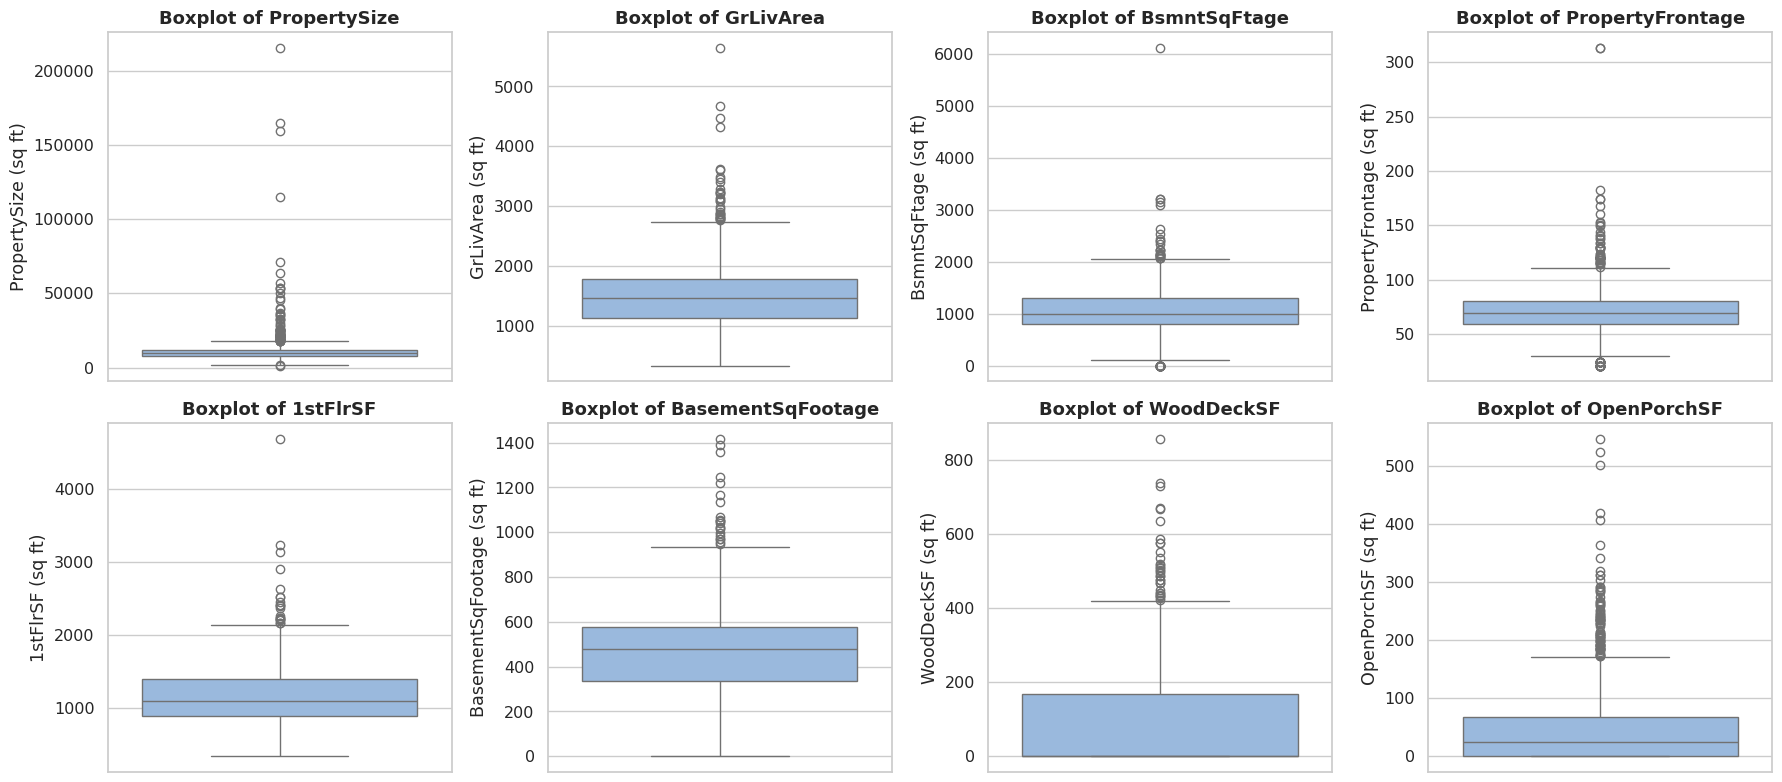

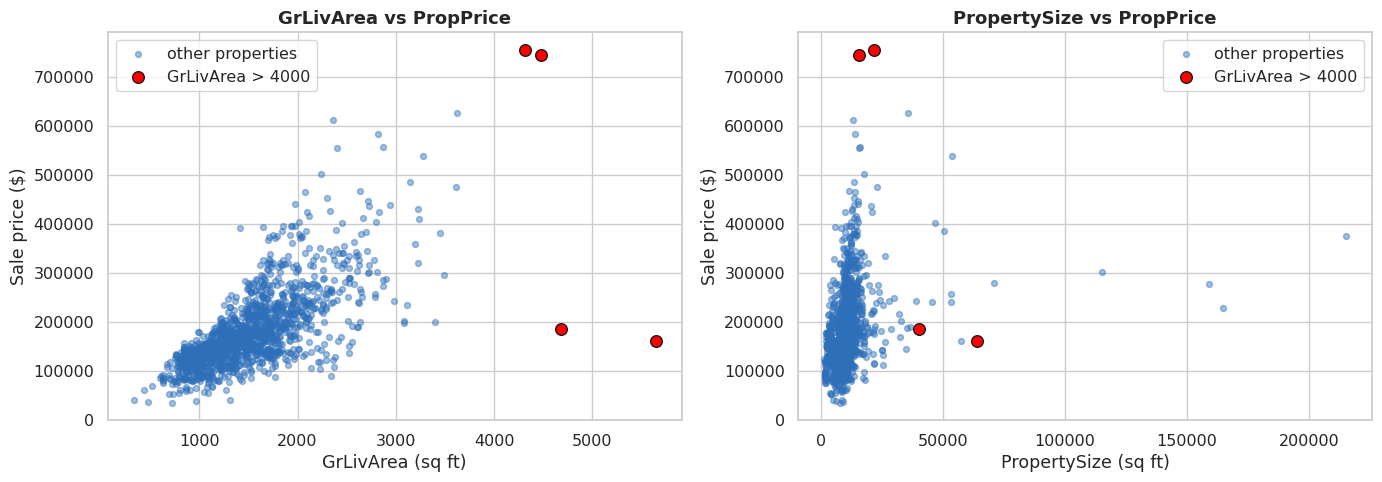

,PropertyID,GrLivArea,OverallQual,Neighborhood,SaleCondn,SaleType,PropPrice
523,524,4676,10,Edwards,Partial,New,184750
691,692,4316,10,NoRidge,Normal,WD,755000
1182,1183,4476,10,NoRidge,Abnorml,WD,745000
1298,1299,5642,10,Edwards,Partial,New,160000


In [17]:
num_df = cleaned.select_dtypes(include=np.number)
rows = []
for c in num_df.columns:
    s = num_df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([c, int(((s < lo) | (s > hi)).sum()), round(100 * ((s < lo) | (s > hi)).mean(), 1), s.quantile(.99), s.max()])
out_tbl = pd.DataFrame(rows, columns=["Column", "IQR outliers", "% outliers", "99th percentile", "Maximum"]).sort_values("IQR outliers", ascending=False)
display(out_tbl.head(12).round(1))

fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for a, c in zip(ax.ravel(), ["PropertySize", "GrLivArea", "BsmntSqFtage", "PropertyFrontage", "1stFlrSF", "BasementSqFootage", "WoodDeckSF", "OpenPorchSF"]):
    sns.boxplot(y=cleaned[c], color="#8FB8E8", ax=a); a.set_title(f"Boxplot of {c}"); a.set_ylabel(c + " (sq ft)")
save_fig("03_outlier_boxplots")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
big = df.GrLivArea > 4000
for a, c in zip(ax, ["GrLivArea", "PropertySize"]):
    a.scatter(df.loc[~big, c], df.loc[~big, TARGET], alpha=.45, s=18, color="#2E6FBA", label="other properties")
    a.scatter(df.loc[big, c], df.loc[big, TARGET], s=70, color="red", edgecolor="k", label="GrLivArea > 4000")
    a.set_title(f"{c} vs PropPrice"); a.set_xlabel(c + " (sq ft)"); a.set_ylabel("Sale price ($)"); a.legend()
save_fig("04_outlier_scatter")
display(df.loc[big, ["PropertyID", "GrLivArea", "OverallQual", "Neighborhood", "SaleCondn", "SaleType", "PropPrice"]])

**Insight:** Four houses exceed 4,000 sq ft of living area. Two of them (IDs 524 and 1299) are `Partial` sales at only $184,750 and $160,000 - far below what their size and top quality would suggest, because a *partial* sale reflects an unfinished property. The other two (IDs 692 and 1183, NoRidge) sold for $755,000 and $745,000 and follow the size-price trend, so they are **genuine high-value properties and are kept**. Other IQR 'outliers' (large lots, porches, decks) are valid observations in a real property market and are kept. The effect of the two abnormal sales on model training is tested in Section 18.1.

## 13. Exploratory Data Analysis (EDA)

EDA is used only to *understand* the data. No statistic from EDA is fed into the model; every learned transformation is fitted later inside a Pipeline on training data.

### 13.1 Univariate analysis

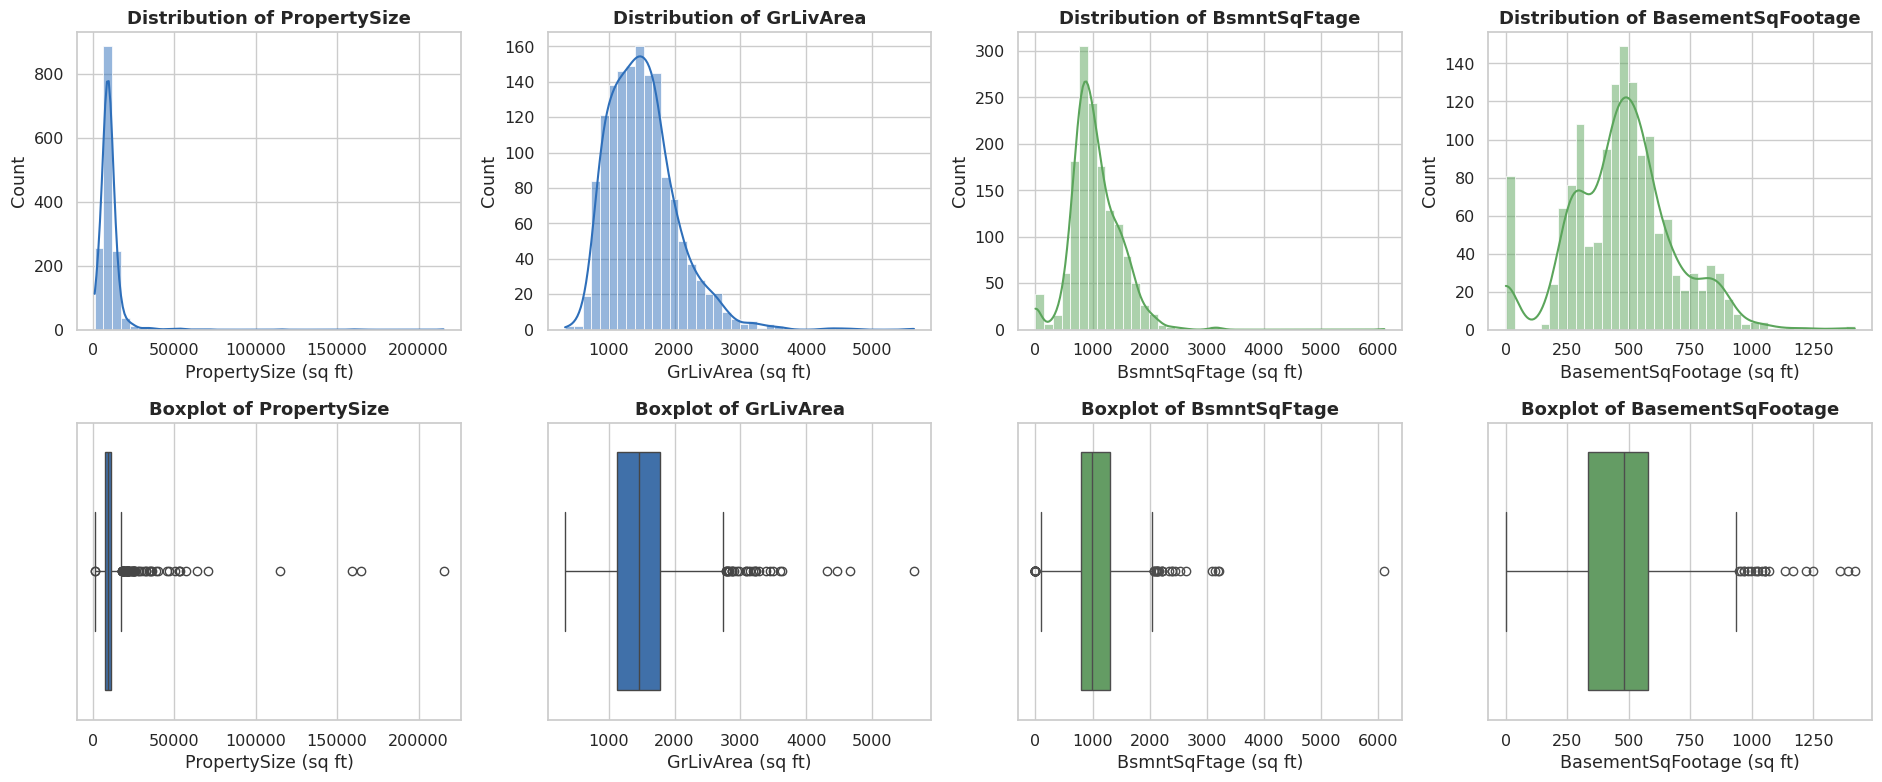

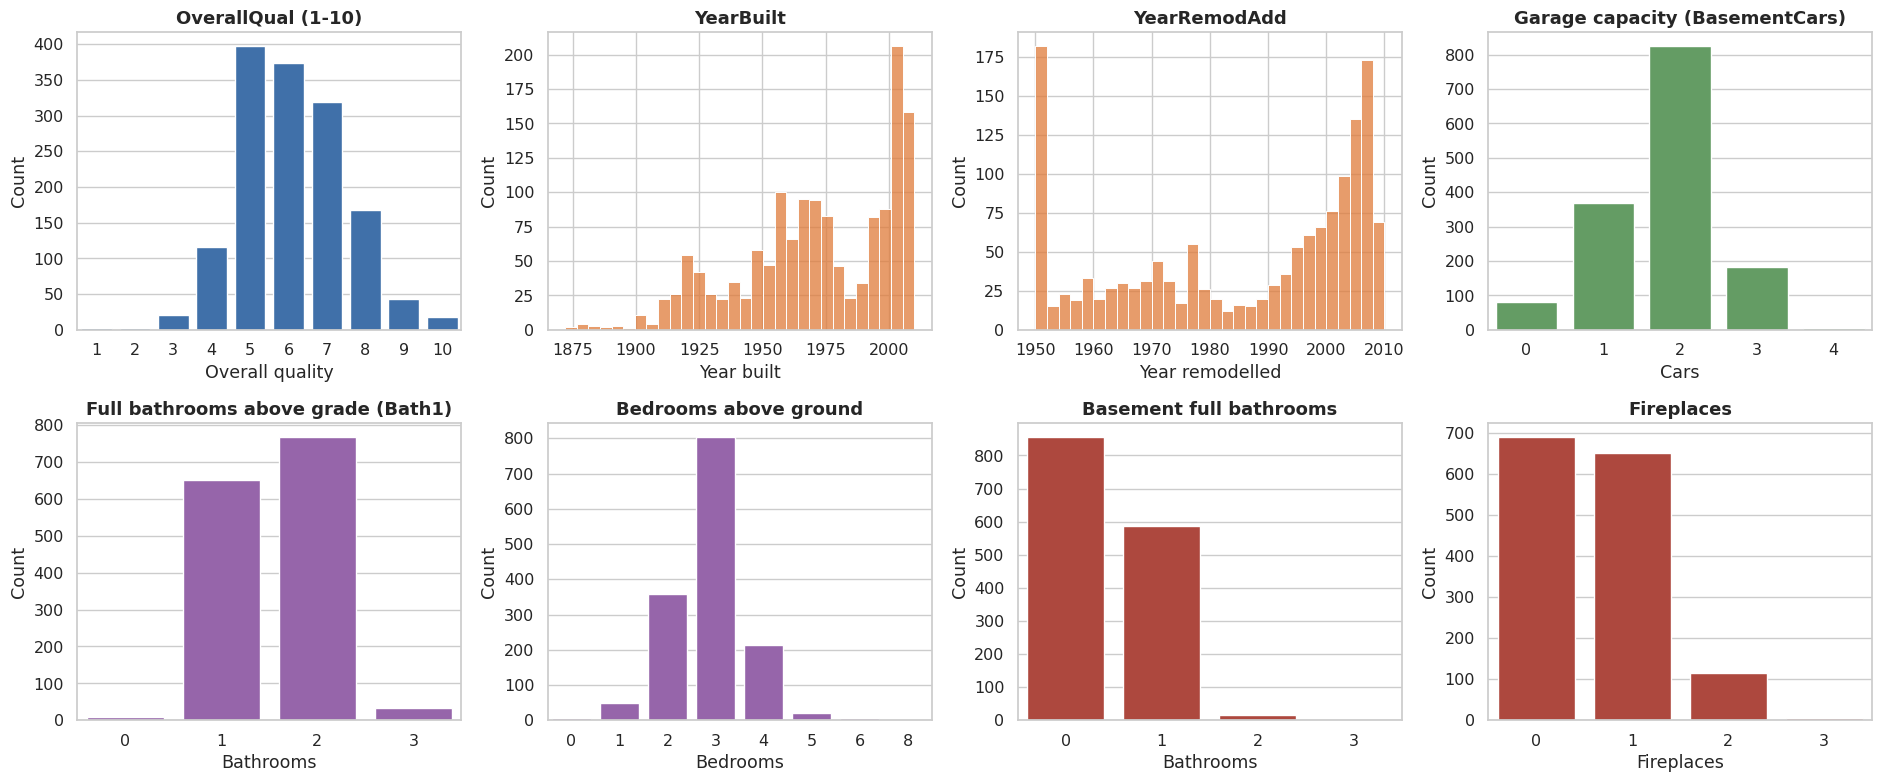

,count,mean,std,min,25%,50%,75%,max
PropertySize,1460.0,10516.8,9981.3,1300.0,7553.5,9478.5,11601.5,215245.0
GrLivArea,1460.0,1515.5,525.5,334.0,1129.5,1464.0,1776.8,5642.0
BsmntSqFtage,1460.0,1057.4,438.7,0.0,795.8,991.5,1298.2,6110.0
BasementSqFootage,1460.0,473.0,213.8,0.0,334.5,480.0,576.0,1418.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0
OverallQual,1460.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0


In [18]:
fig, ax = plt.subplots(2, 4, figsize=(19, 8))
for i, (c, col) in enumerate([("PropertySize", "#2E6FBA"), ("GrLivArea", "#2E6FBA"), ("BsmntSqFtage", "#5BA55B"), ("BasementSqFootage", "#5BA55B")]):
    sns.histplot(df[c], bins=40, kde=True, color=col, ax=ax[0, i]); ax[0, i].set_title(f"Distribution of {c}")
    ax[0, i].set_xlabel(c + " (sq ft)"); ax[0, i].set_ylabel("Count")
    sns.boxplot(x=df[c], color=col, ax=ax[1, i]); ax[1, i].set_title(f"Boxplot of {c}"); ax[1, i].set_xlabel(c + " (sq ft)")
save_fig("05_univariate_areas")

fig, ax = plt.subplots(2, 4, figsize=(19, 8))
sns.countplot(x=df.OverallQual, color="#2E6FBA", ax=ax[0, 0]); ax[0, 0].set_title("OverallQual (1-10)"); ax[0, 0].set_xlabel("Overall quality"); ax[0, 0].set_ylabel("Count")
sns.histplot(df.YearBuilt, bins=30, color="#E07B39", ax=ax[0, 1]); ax[0, 1].set_title("YearBuilt"); ax[0, 1].set_xlabel("Year built"); ax[0, 1].set_ylabel("Count")
sns.histplot(df.YearRemodAdd, bins=30, color="#E07B39", ax=ax[0, 2]); ax[0, 2].set_title("YearRemodAdd"); ax[0, 2].set_xlabel("Year remodelled"); ax[0, 2].set_ylabel("Count")
sns.countplot(x=df.BasementCars, color="#5BA55B", ax=ax[0, 3]); ax[0, 3].set_title("Garage capacity (BasementCars)"); ax[0, 3].set_xlabel("Cars"); ax[0, 3].set_ylabel("Count")
sns.countplot(x=df.Bath1, color="#9B59B6", ax=ax[1, 0]); ax[1, 0].set_title("Full bathrooms above grade (Bath1)"); ax[1, 0].set_xlabel("Bathrooms"); ax[1, 0].set_ylabel("Count")
sns.countplot(x=df.BedroomUpLev, color="#9B59B6", ax=ax[1, 1]); ax[1, 1].set_title("Bedrooms above ground"); ax[1, 1].set_xlabel("Bedrooms"); ax[1, 1].set_ylabel("Count")
sns.countplot(x=df.BsmtFullBath, color="#C0392B", ax=ax[1, 2]); ax[1, 2].set_title("Basement full bathrooms"); ax[1, 2].set_xlabel("Bathrooms"); ax[1, 2].set_ylabel("Count")
sns.countplot(x=df.CntFireplaces, color="#C0392B", ax=ax[1, 3]); ax[1, 3].set_title("Fireplaces"); ax[1, 3].set_xlabel("Fireplaces"); ax[1, 3].set_ylabel("Count")
save_fig("06_univariate_counts")
display(df[["PropertySize", "GrLivArea", "BsmntSqFtage", "BasementSqFootage", "YearBuilt", "OverallQual"]].describe().T.round(1))

**Insights:** Living area, basement area and especially lot size are right-skewed with a few very large properties (lot size: mean 10,517 sq ft but standard deviation 9,981). `OverallQual` is centred around 5-7 (mean 6.1) - most homes are average-to-good quality. Houses were built between 1872 and 2010 (mean year 1971) and the remodel years start in 1950. A typical property has about 3 bedrooms (mean 2.87), 1-2 full bathrooms (mean 1.57) and a garage for 1-2 cars; most have no or one fireplace.

### 13.2 Bivariate analysis

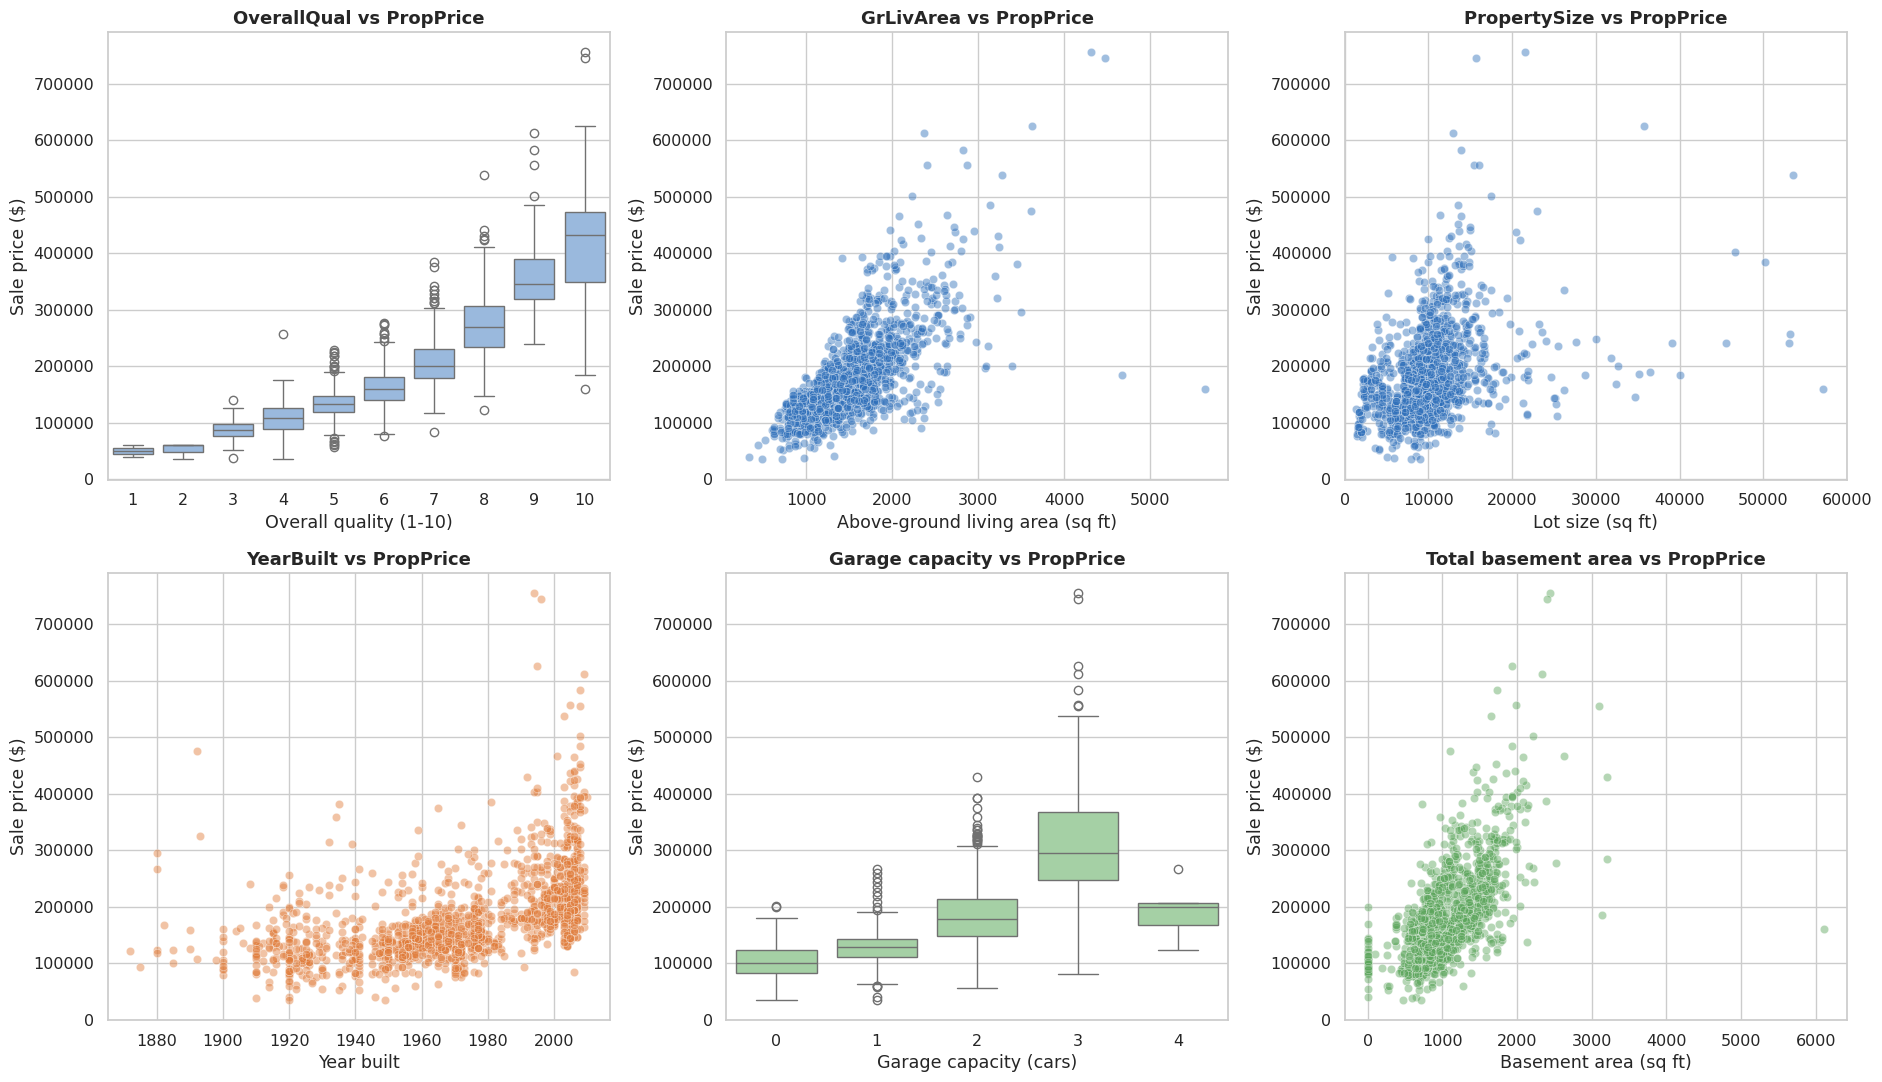

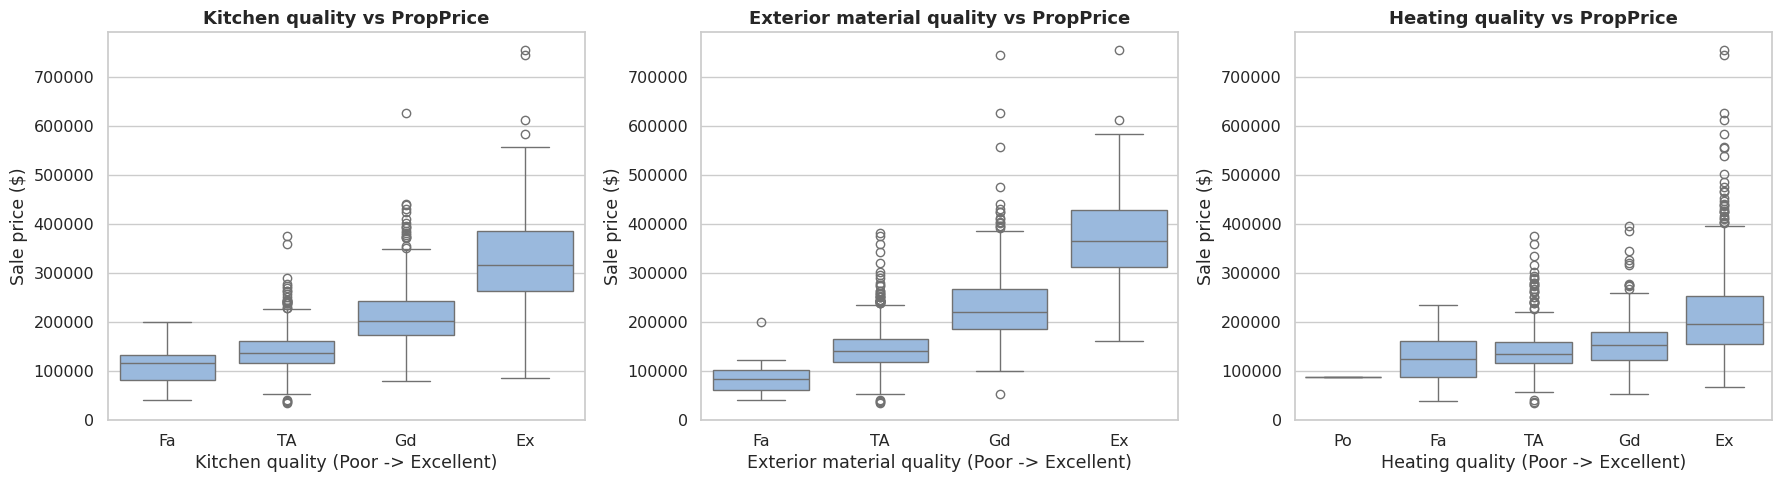

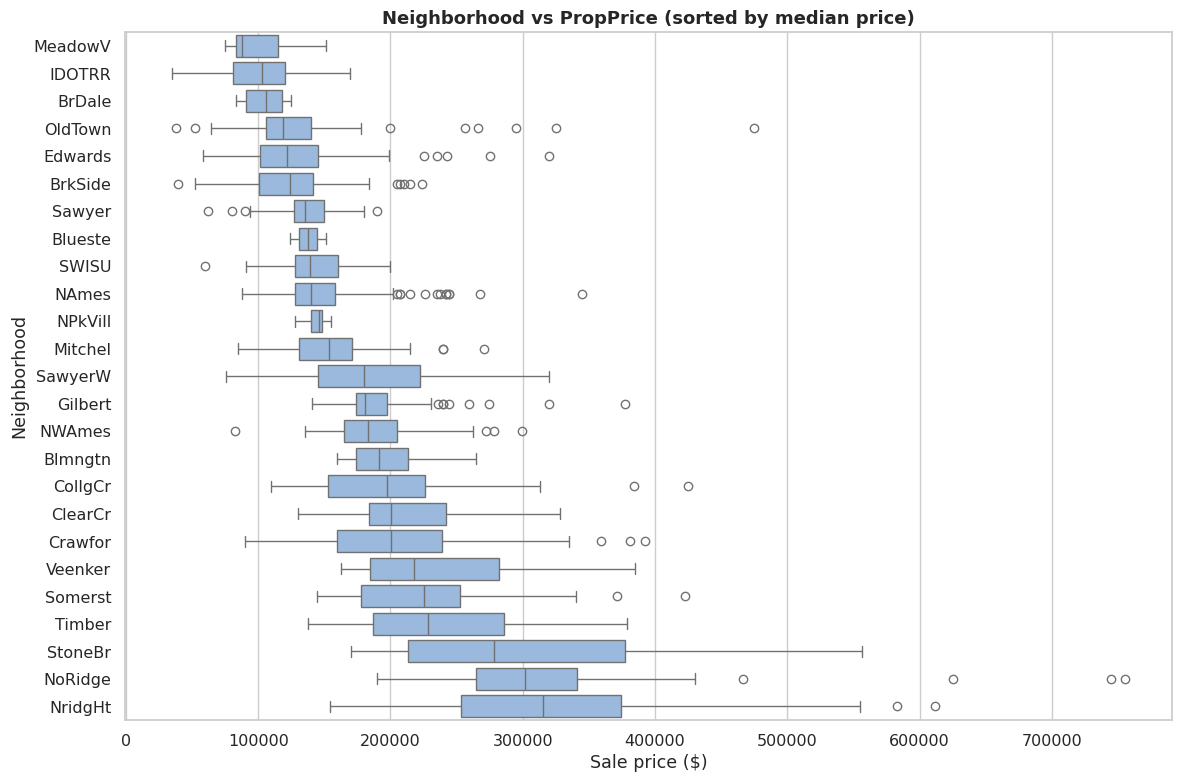

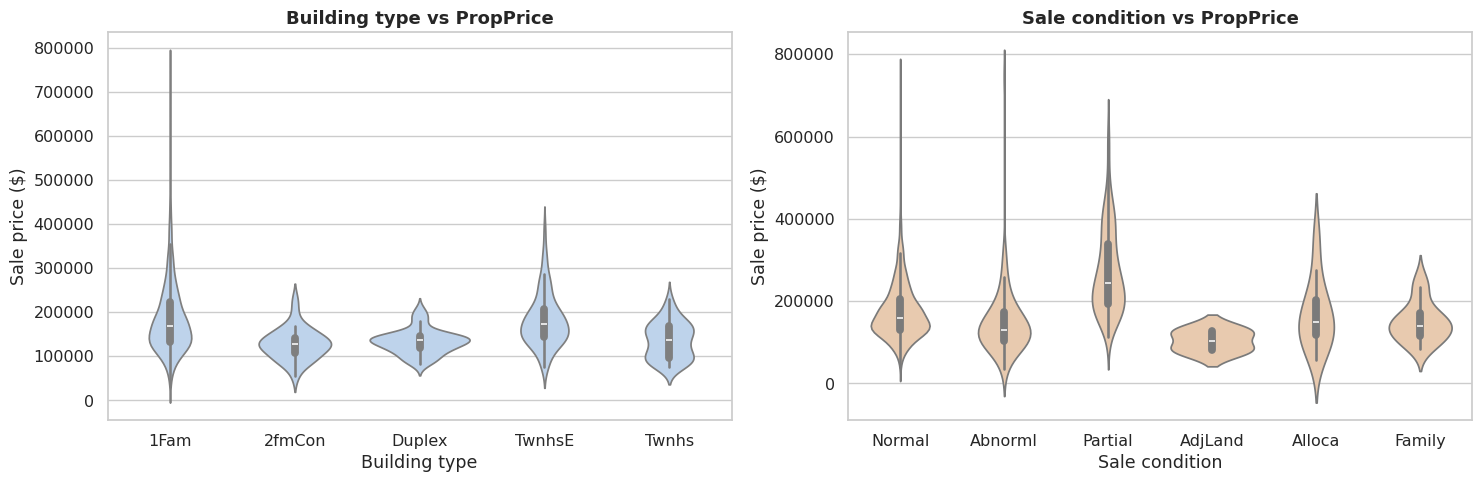

Neighborhood,MeadowV,IDOTRR,BrDale,OldTown,Edwards,BrkSide,Sawyer,Blueste,SWISU,NAmes,NPkVill,Mitchel,SawyerW,Gilbert,NWAmes,Blmngtn,CollgCr,ClearCr,Crawfor,Veenker,Somerst,Timber,StoneBr,NoRidge,NridgHt
count,17.0,37.0,16.0,113.0,100.0,58.0,74.0,2.0,25.0,225.0,9.0,49.0,59.0,79.0,73.0,17.0,150.0,28.0,51.0,11.0,86.0,38.0,25.0,41.0,77.0
median,88000.0,103000.0,106000.0,119000.0,121750.0,124300.0,135000.0,137500.0,139500.0,140000.0,146000.0,153500.0,179900.0,181000.0,182900.0,191000.0,197200.0,200250.0,200624.0,218000.0,225500.0,228475.0,278000.0,301500.0,315000.0


,median price
KitchenQual,
Ex,316750.0
Fa,115000.0
Gd,201400.0
TA,137000.0


In [19]:
fig, ax = plt.subplots(2, 3, figsize=(19, 11))
sns.boxplot(x="OverallQual", y=TARGET, data=df, color="#8FB8E8", ax=ax[0, 0]); ax[0, 0].set_title("OverallQual vs PropPrice"); ax[0, 0].set_xlabel("Overall quality (1-10)"); ax[0, 0].set_ylabel("Sale price ($)")
sns.scatterplot(x="GrLivArea", y=TARGET, data=df, alpha=.45, color="#2E6FBA", ax=ax[0, 1]); ax[0, 1].set_title("GrLivArea vs PropPrice"); ax[0, 1].set_xlabel("Above-ground living area (sq ft)"); ax[0, 1].set_ylabel("Sale price ($)")
sns.scatterplot(x="PropertySize", y=TARGET, data=df, alpha=.45, color="#2E6FBA", ax=ax[0, 2]); ax[0, 2].set_title("PropertySize vs PropPrice"); ax[0, 2].set_xlabel("Lot size (sq ft)"); ax[0, 2].set_ylabel("Sale price ($)"); ax[0, 2].set_xlim(0, 60000)
sns.scatterplot(x="YearBuilt", y=TARGET, data=df, alpha=.45, color="#E07B39", ax=ax[1, 0]); ax[1, 0].set_title("YearBuilt vs PropPrice"); ax[1, 0].set_xlabel("Year built"); ax[1, 0].set_ylabel("Sale price ($)")
sns.boxplot(x="BasementCars", y=TARGET, data=df, color="#9ED79E", ax=ax[1, 1]); ax[1, 1].set_title("Garage capacity vs PropPrice"); ax[1, 1].set_xlabel("Garage capacity (cars)"); ax[1, 1].set_ylabel("Sale price ($)")
sns.scatterplot(x="BsmntSqFtage", y=TARGET, data=df, alpha=.45, color="#5BA55B", ax=ax[1, 2]); ax[1, 2].set_title("Total basement area vs PropPrice"); ax[1, 2].set_xlabel("Basement area (sq ft)"); ax[1, 2].set_ylabel("Sale price ($)")
save_fig("07_bivariate_numeric")

qual_order = ["Fa", "TA", "Gd", "Ex"]
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, c, t in zip(ax, ["KitchenQual", "ExterQual", "HeatingEfficiency"], ["Kitchen quality", "Exterior material quality", "Heating quality"]):
    order = [q for q in ["Po", "Fa", "TA", "Gd", "Ex"] if q in df[c].unique()]
    sns.boxplot(x=c, y=TARGET, data=df, order=order, color="#8FB8E8", ax=a); a.set_title(f"{t} vs PropPrice"); a.set_xlabel(t + " (Poor -> Excellent)"); a.set_ylabel("Sale price ($)")
save_fig("08_bivariate_quality")

order = df.groupby("Neighborhood")[TARGET].median().sort_values().index
plt.figure(figsize=(12, 8))
sns.boxplot(y="Neighborhood", x=TARGET, data=df, order=order, color="#8FB8E8")
plt.title("Neighborhood vs PropPrice (sorted by median price)"); plt.xlabel("Sale price ($)"); plt.ylabel("Neighborhood")
save_fig("09_neighborhood_price")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.violinplot(x="BldgType", y=TARGET, data=df, color="#B7D3F2", ax=ax[0]); ax[0].set_title("Building type vs PropPrice"); ax[0].set_xlabel("Building type"); ax[0].set_ylabel("Sale price ($)")
sns.violinplot(x="SaleCondn", y=TARGET, data=df, color="#F2C9A5", ax=ax[1]); ax[1].set_title("Sale condition vs PropPrice"); ax[1].set_xlabel("Sale condition"); ax[1].set_ylabel("Sale price ($)")
save_fig("10_violin_bldg_salecond")

nb = df.groupby("Neighborhood")[TARGET].agg(["count", "median"]).sort_values("median")
RES["nb_low"] = nb.head(3)["median"].to_dict(); RES["nb_high"] = nb.tail(3)["median"].to_dict()
RES["qual_median"] = df.groupby("OverallQual")[TARGET].median().to_dict()
display(nb.T.round(0))
display(df.groupby("KitchenQual")[TARGET].median().to_frame("median price"))

**Insights:** (1) **Quality is the strongest pattern**: the median price rises from $50,150 at OverallQual 1 to $200,141 at 7 and $432,390 at 10. (2) Price grows almost linearly with `GrLivArea`; the two `Partial` mega-houses are visible as points far below the trend. (3) Lot size has only a weak relationship - a bigger plot does not guarantee a higher price. (4) Newer houses sell for more (`YearBuilt`). (5) Garage capacity matters up to 3 cars, basement area has a clear positive trend. (6) Better kitchen/exterior quality means higher price. (7) **Location matters**: median price is lowest in MeadowV ($88,000), IDOTRR ($103,000) and BrDale ($106,000) and highest in NridgHt ($315,000), NoRidge ($301,500) and StoneBr ($278,000) - a 3.5x difference between neighbourhoods.

### 13.3 Correlation analysis

,correlation with PropPrice
OverallQual,0.791
GrLivArea,0.709
BasementCars,0.640
BasementSqFootage,0.623
BsmntSqFtage,0.614
1stFlrSF,0.606
Bath1,0.561
CntRmsUpLev,0.534
YearBuilt,0.523
YearRemodAdd,0.507


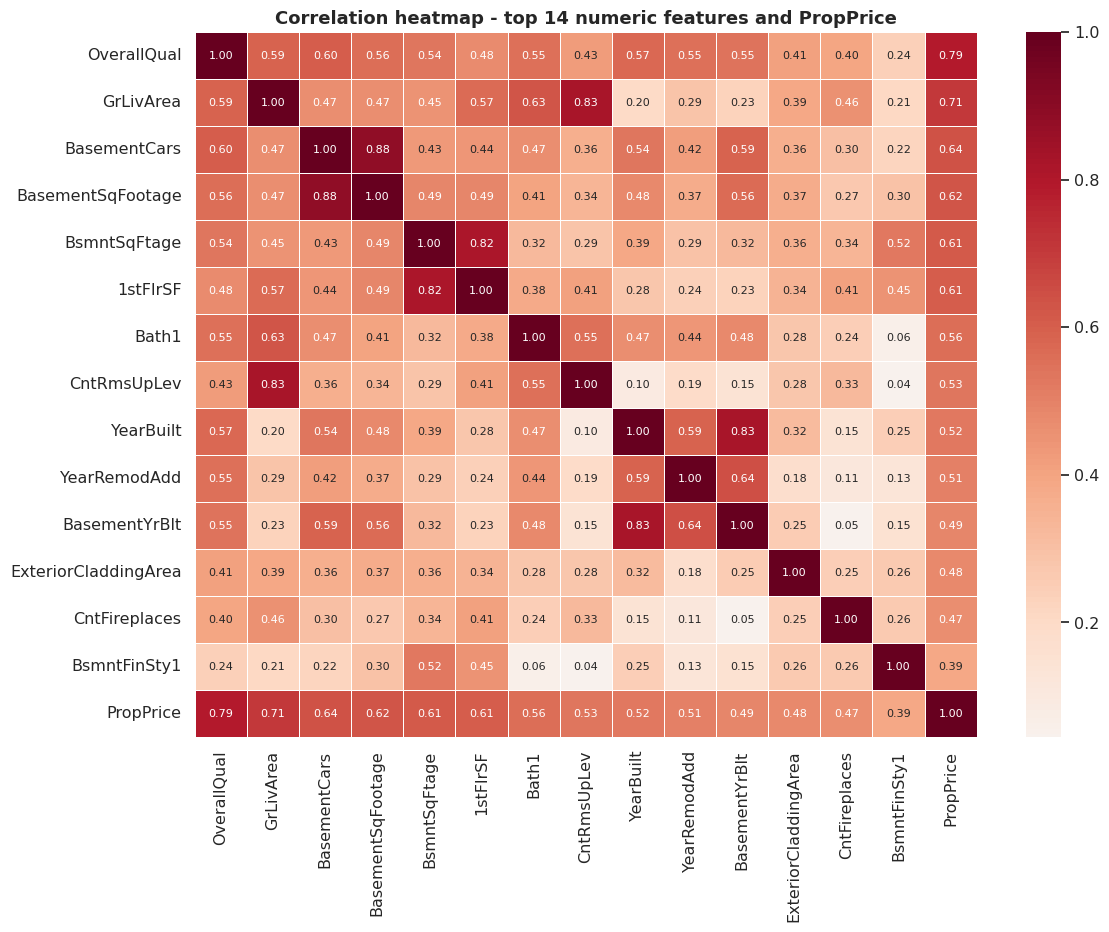

,,|correlation|
BasementCars,BasementSqFootage,0.88
YearBuilt,BasementYrBlt,0.83
GrLivArea,CntRmsUpLev,0.83
BsmntSqFtage,1stFlrSF,0.82


In [20]:
num_for_corr = df.drop(columns=[ID_COL]).select_dtypes(include=np.number)
corr = num_for_corr.corr()
top = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
display(top.head(15).round(3).to_frame("correlation with PropPrice"))
RES["top_corr"] = top.head(12).round(3).to_dict()

cols = list(top.head(14).index) + [TARGET]
plt.figure(figsize=(12, 9.5))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=.4, annot_kws={"size": 8})
plt.title("Correlation heatmap - top 14 numeric features and PropPrice")
save_fig("11_correlation_heatmap")

# strongly inter-correlated feature pairs (multicollinearity)
c2 = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
pairs = c2[c2 > 0.8].round(2).to_frame("|correlation|"); display(pairs)
RES["collinear_pairs"] = {f"{a} & {b}": float(v) for (a, b), v in pairs["|correlation|"].items()}

**Insights:** The numeric features most correlated with `PropPrice` are `OverallQual` (0.79), `GrLivArea` (0.71), garage capacity `BasementCars` (0.64), garage area (0.62), basement area (0.61), `1stFlrSF` (0.61), `Bath1` (0.56), `CntRmsUpLev` (0.53) and `YearBuilt` (0.52). Strongly inter-correlated pairs exist (garage cars & garage area 0.88, `YearBuilt` & garage year 0.83, `GrLivArea` & room count 0.83, basement area & `1stFlrSF` 0.82) - this *multicollinearity* is one reason why **regularised** linear models (Ridge/Lasso) are expected to be stable. Remember: correlation does **not** prove causation (e.g. a bigger garage does not by itself raise the price; it travels together with a bigger, newer, better house).

## 14. Feature Engineering

New features are built from **domain knowledge** (what a buyer actually looks at). Each uses only values from the *same* row, so there is no leakage.

| New feature | Formula | Idea |
|---|---|---|
| `TotalSF` | basement + 1st floor + 2nd floor | total usable area |
| `TotalBathrooms` | full + 0.5 x half (above grade and basement) | bathroom capacity |
| `TotalPorchSF` | open + enclosed + 3-season + screen porch + wood deck | outdoor living space |
| `HouseAge` | `SaleYr - YearBuilt` | older houses are usually cheaper |
| `RemodelAge` | `SaleYr - YearRemodAdd` | how fresh is the renovation |
| `IsRemodeled` | remodel year differs from build year | renovation flag |
| `HasGarage`, `HasBasement`, `HasPool`, `Has2ndFloor`, `HasFireplace` | area/count > 0 | simple presence flags |
| `QualxLivArea` | `OverallQual x GrLivArea` | big *and* high-quality houses are worth much more (interaction) |

The original columns are **kept** (nothing is dropped). Whether the new features really help is tested objectively in Section 18.

,count,mean,std,min,25%,50%,75%,max
TotalSF,1460.0,2567.05,821.71,334.0,2009.5,2474.0,3004.0,11752.0
TotalBathrooms,1460.0,2.21,0.79,1.0,2.0,2.0,2.5,6.0
TotalPorchSF,1460.0,181.33,156.66,0.0,45.0,164.0,266.0,1027.0
HouseAge,1460.0,36.55,30.25,0.0,8.0,35.0,54.0,136.0
RemodelAge,1460.0,22.95,20.64,0.0,4.0,14.0,41.0,60.0
IsRemodeled,1460.0,0.48,0.50,0.0,0.0,0.0,1.0,1.0
HasGarage,1460.0,0.94,0.23,0.0,1.0,1.0,1.0,1.0
HasBasement,1460.0,0.97,0.16,0.0,1.0,1.0,1.0,1.0
HasPool,1460.0,0.00,0.07,0.0,0.0,0.0,0.0,1.0
Has2ndFloor,1460.0,0.43,0.50,0.0,0.0,0.0,1.0,1.0


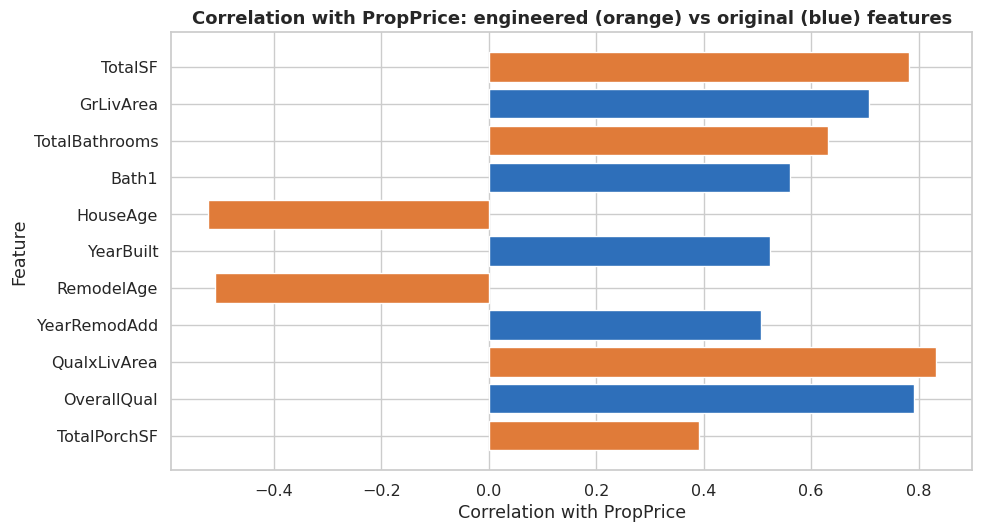

,TotalSF,GrLivArea,TotalBathrooms,Bath1,HouseAge,YearBuilt,RemodelAge,YearRemodAdd,QualxLivArea,OverallQual,TotalPorchSF
corr with PropPrice,0.782,0.709,0.632,0.561,-0.523,0.523,-0.509,0.507,0.832,0.791,0.391


In [21]:
eng = add_features(cleaned)
new_feats = ["TotalSF", "TotalBathrooms", "TotalPorchSF", "HouseAge", "RemodelAge", "IsRemodeled",
             "HasGarage", "HasBasement", "HasPool", "Has2ndFloor", "HasFireplace", "QualxLivArea"]
display(eng[new_feats].describe().T.round(2))

cmp_cols = ["TotalSF", "GrLivArea", "TotalBathrooms", "Bath1", "HouseAge", "YearBuilt", "RemodelAge", "YearRemodAdd", "QualxLivArea", "OverallQual", "TotalPorchSF"]
cc = eng[cmp_cols].assign(PropPrice=df[TARGET]).corr()[TARGET].drop(TARGET)
plt.figure(figsize=(10, 5.5))
colors = ["#E07B39" if c in new_feats else "#2E6FBA" for c in cc.index]
plt.barh(cc.index, cc.values, color=colors)
plt.title("Correlation with PropPrice: engineered (orange) vs original (blue) features")
plt.xlabel("Correlation with PropPrice"); plt.ylabel("Feature"); plt.gca().invert_yaxis()
save_fig("12_engineered_feature_correlation")
RES["fe_corr"] = cc.round(3).to_dict()
display(cc.round(3).to_frame("corr with PropPrice").T)

**Insight:** Several engineered features correlate more strongly with the price than the original columns they were built from: `QualxLivArea` 0.83 (vs 0.79 for `OverallQual` and 0.71 for `GrLivArea`), `TotalSF` 0.78 (vs 0.71 for `GrLivArea`) and `TotalBathrooms` 0.63 (vs 0.56 for `Bath1`). `HouseAge` and `RemodelAge` are negatively correlated (-0.52 / -0.51), i.e. older/less recently renovated houses are cheaper. Correlation alone is not proof - the real test follows below.

## 15. Data Leakage Check

**Data leakage** means information from the validation/test data (or from the target) sneaks into model training. The model then looks great on paper but fails on new properties. Our safeguards:

| Risk | Safeguard in this project |
|---|---|
| Target used as input | `PropPrice` and `PropertyID` are dropped inside `clean_data()` |
| Imputation learning from all data | `SimpleImputer` lives **inside the Pipeline** -> fitted on training folds only |
| Scaling / log-skew rule learnt from all data | `StandardScaler` and `SkewFixer` are inside the Pipeline |
| Encoding learnt from all data | `OneHotEncoder` / `OrdinalEncoder` inside the Pipeline (`handle_unknown` set) |
| PCA fitted on all data | `PCA` is a Pipeline step -> fitted on training folds only |
| Tuning on the test set | `GridSearchCV`/`RandomizedSearchCV` use **cross-validation on the training part only** |
| Model selection on the test set | models are compared on **validation** set + CV; the hold-out **test set is used once** |
| Row-wise cleaning / feature engineering | uses only the same row, no statistics from other rows |

## 16. Train / Validation / Test Strategy

* **70 % train** - fit models and run cross-validation / hyper-parameter search
* **15 % validation** - compare models and select the final one
* **15 % hold-out test** - final, one-time evaluation

The split is **stratified by price decile**, so cheap, medium and expensive properties appear in the same proportions in every part.

In [22]:
X = df.drop(columns=[TARGET])        # PropertyID is removed later inside the pipeline (clean_data)
y = df[TARGET]
price_bins = pd.qcut(y, 10, labels=False)

X_dev, X_test, y_dev, y_test, bins_dev, _ = train_test_split(X, y, price_bins, test_size=0.15, random_state=RANDOM_STATE, stratify=price_bins)
X_train, X_valid, y_train, y_valid = train_test_split(X_dev, y_dev, test_size=0.1765, random_state=RANDOM_STATE, stratify=bins_dev)

split_tbl = pd.DataFrame({
    "Rows": [len(X_train), len(X_valid), len(X_test)],
    "Share %": [round(100 * len(a) / len(X), 1) for a in (X_train, X_valid, X_test)],
    "Mean price": [y_train.mean(), y_valid.mean(), y_test.mean()],
    "Median price": [y_train.median(), y_valid.median(), y_test.median()],
}, index=["Train", "Validation", "Hold-out test"]).round(0)
display(split_tbl)
RES["split"] = {k: int(v) for k, v in zip(["train", "valid", "test"], split_tbl.Rows)}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)      # used for every cross-validation

# Rule for non-representative sales (decided from FEATURES only, never from the target):
# very large houses (> 4000 sq ft) sold as 'Partial' (house not finished when assessed).
def abnormal_mask(Xd):
    return (Xd["GrLivArea"] > 4000) & (Xd["SaleCondn"] == "Partial")

def drop_abnormal(Xd, yd):
    keep = ~abnormal_mask(Xd)
    return Xd[keep], yd[keep]

def cv_r2(model, Xd=None, yd=None):
    """5-fold CV R2 on the TRAIN part. Returns (mean, std)."""
    s = cross_val_score(model, X_train if Xd is None else Xd, y_train if yd is None else yd, cv=cv, scoring="r2")
    return s.mean(), s.std()

def evaluate(model, Xe, ye):
    p = model.predict(Xe)
    return {"R2": r2_score(ye, p), "MAE": mean_absolute_error(ye, p), "RMSE": root_mean_squared_error(ye, p)}

,Rows,Share %,Mean price,Median price
Train,1021,70.0,180714.0,163000.0
Validation,220,15.0,180656.0,163200.0
Hold-out test,219,15.0,182155.0,163990.0


## 17. Preprocessing Pipeline

`prepare_df` (cleaning + features) -> `ColumnTransformer` -> *(optional PCA)* -> model.

* **Linear models, PCA** -> scaled version (median imputation, log for skewed numbers, `StandardScaler`).
* **Tree models** -> unscaled version. Trees split on thresholds, so monotonic transformations such as scaling do not change them.

**Why scaling matters for Linear/Ridge/Lasso/ElasticNet/SVR/PCA:** these methods use coefficient penalties or variances. If `PropertySize` ranges to 200,000 and `OverallQual` only 1-10, large-valued columns would dominate the penalty and the principal components. Scaling puts every feature on the same footing.

In [23]:
enc_demo = build_encoder(scaled=True)
Z = enc_demo.fit_transform(prepare_df(X_train))            # fitted on TRAIN only
names = enc_demo.get_feature_names_out()
print("Rows x encoded features (train):", Z.shape)
n_nom = sum(any(n.startswith(c + "_") for c in NOMINAL_COLS) for n in names)
print(f"  numeric (+missing-indicators) : {len([n for n in names if n not in ORDINAL_COLS]) - n_nom}")
print(f"  ordinal columns               : {len(ORDINAL_COLS)}")
print(f"  one-hot nominal columns       : {n_nom}")
print("Any NaN left after preprocessing?", bool(np.isnan(Z).any()))

# apply the SAME fitted encoder to validation: identical columns, no refitting
Zv = enc_demo.transform(prepare_df(X_valid))
print("Validation encoded shape:", Zv.shape, "(same number of columns as train)")
display(pd.DataFrame(Z[:3, :8], columns=names[:8]).round(2))
RES["n_encoded_features"] = int(Z.shape[1])

Rows x encoded features (train): (1021, 261)
  numeric (+missing-indicators) : 49
  ordinal columns               : 22
  one-hot nominal columns       : 190
Any NaN left after preprocessing? False
Validation encoded shape: (220, 261) (same number of columns as train)


,PropertyFrontage,PropertySize,OverallQual,OverallCond,YearBuilt,YearRemodAdd,ExteriorCladdingArea,BsmntFinSty1
0,1.09,0.26,0.65,-0.49,1.23,1.17,-0.83,-1.41
1,0.57,0.11,0.65,0.41,0.04,-0.58,1.36,0.86
2,-0.46,0.86,0.65,-0.49,1.13,1.03,-0.83,-1.41


## 18. Experiments Before Choosing Models

Every decision below is tested with data (cross-validation on the training part and/or the validation set), not assumed.

### 18.1 Should we train without the non-representative `Partial` mega-house sales?
Four houses are extremely large (> 4000 sq ft). Two of them are `Partial` sales (house not finished when assessed, ~$160-185k for 4,600-5,600 sq ft) and sell far below what their size and quality suggest, which can badly distort a model. The rule uses **features only** (`GrLivArea > 4000` and `SaleCondn == "Partial"`), never the target. We test objectively whether leaving such rows out of the **training** data helps; the validation set stays untouched. The two very expensive large houses (genuine luxury sales) are always **kept**.

In [24]:
abn_rows = X_train[abnormal_mask(X_train)]
print("Rows matching the rule inside TRAIN:", abn_rows[ID_COL].tolist(), "| prices:", y_train.loc[abn_rows.index].tolist())
rows = []
for name, est, scaled in [("Ridge (alpha=10)", Ridge(alpha=10), True), ("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE), False)]:
    for drop in [False, True]:
        Xa, ya = drop_abnormal(X_train, y_train) if drop else (X_train, y_train)
        mdl = make_model(est, scaled=scaled)
        cm, cs = cv_r2(mdl, Xa, ya)
        mdl.fit(Xa, ya); r = evaluate(mdl, X_valid, y_valid)
        rows.append([name, "dropped from training" if drop else "kept", cm, cs, r["R2"], r["MAE"], r["RMSE"]])
out_cmp = pd.DataFrame(rows, columns=["Model", "Abnormal rows", "CV R2 mean", "CV R2 std", "Valid R2", "Valid MAE", "Valid RMSE"]).round(4)
display(out_cmp)
RES["outlier_compare"] = out_cmp.to_dict("records")

Rows matching the rule inside TRAIN: [1299, 524] | prices: [160000, 184750]


,Model,Abnormal rows,CV R2 mean,CV R2 std,Valid R2,Valid MAE,Valid RMSE
0,Ridge (alpha=10),kept,0.7271,0.2775,0.9282,14542.5896,20464.0190
1,Ridge (alpha=10),dropped from training,0.9076,0.0167,0.9450,13043.5504,17908.6125
2,Gradient Boosting,kept,0.8819,0.0253,0.9021,15884.9576,23891.4613
3,Gradient Boosting,dropped from training,0.9112,0.0230,0.9117,15465.3411,22696.3319


**Decision: drop the 2 non-representative `Partial` mega-house sales from the training data only.** With them kept, Ridge's cross-validation R² was only 0.727 with a huge fold-to-fold spread (std 0.28) because the model tried to fit prices that make no sense for their size; after dropping them it rises to **0.908 (std 0.017)** and validation R² improves from 0.928 to 0.945. Gradient Boosting also improves (CV 0.882 -> 0.911, validation 0.902 -> 0.912). The rule uses only features (not the target), the two genuine luxury sales stay, and validation/test sets are never altered - so the evaluation remains honest.

In [25]:
# APPLY the decision: remove these rows from the data used to FIT models (validation/test rows are never altered)
n_before = len(X_train)
X_train, y_train = drop_abnormal(X_train, y_train)
X_dev_fit, y_dev_fit = drop_abnormal(X_dev, y_dev)        # train + validation, used for the final evaluation fit
X_all_fit, y_all_fit = drop_abnormal(X, y)                # all labelled data, used for the deployment model
print(f"Training rows: {n_before} -> {len(X_train)} | train+valid: {len(X_dev)} -> {len(X_dev_fit)} | all data: {len(X)} -> {len(X_all_fit)}")
print("Validation rows (unchanged):", len(X_valid), "| Hold-out test rows (unchanged):", len(X_test))
RES["n_dropped_train"] = int(n_before - len(X_train))

Training rows: 1021 -> 1019 | train+valid: 1241 -> 1239 | all data: 1460 -> 1458
Validation rows (unchanged): 220 | Hold-out test rows (unchanged): 219


### 18.2 Does feature engineering help?
Same models, same 5-fold CV on the training part, with and without the engineered features.

,Model,Feature set,CV R2 mean,CV R2 std
0,Ridge (alpha=10),original features only,0.9057,0.0175
1,Ridge (alpha=10),with engineered features,0.9076,0.0167
2,Gradient Boosting,original features only,0.9012,0.0245
3,Gradient Boosting,with engineered features,0.9112,0.0230
4,Random Forest,original features only,0.8697,0.0251
5,Random Forest,with engineered features,0.8848,0.0237


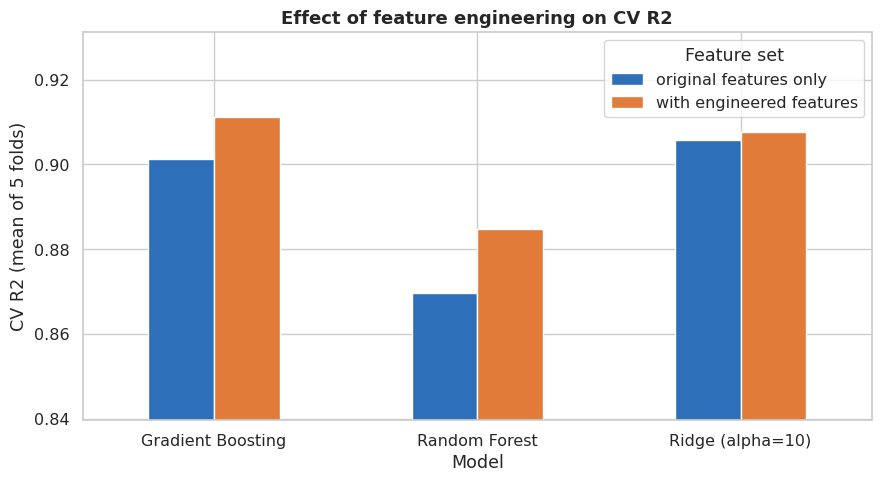

In [26]:
rows = []
for name, est, scaled in [("Ridge (alpha=10)", Ridge(alpha=10), True),
                          ("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE), False),
                          ("Random Forest", RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1), False)]:
    for eng_flag in [False, True]:
        m, s = cv_r2(make_model(est, scaled=scaled, engineer=eng_flag, log_target=True))
        rows.append([name, "with engineered features" if eng_flag else "original features only", m, s])
fe_cmp = pd.DataFrame(rows, columns=["Model", "Feature set", "CV R2 mean", "CV R2 std"]).round(4)
display(fe_cmp)
fe_cmp.to_csv("tables/feature_engineering_comparison.csv", index=False)
RES["fe_compare"] = fe_cmp.to_dict("records")
save_table_image(fe_cmp, "shot_03_feature_engineering", "Feature engineering: before vs after (5-fold CV R2 on train)", col_w=2.4)

piv = fe_cmp.pivot(index="Model", columns="Feature set", values="CV R2 mean")
piv.plot(kind="bar", figsize=(9, 5), color=["#2E6FBA", "#E07B39"]); plt.ylim(piv.values.min() - .03, piv.values.max() + .02)
plt.title("Effect of feature engineering on CV R2"); plt.ylabel("CV R2 (mean of 5 folds)"); plt.xlabel("Model"); plt.xticks(rotation=0)
save_fig("13_feature_engineering_effect")

**Decision: keep the engineered features.** CV R² improves for all three models: Ridge 0.906 -> 0.908, Gradient Boosting 0.901 -> 0.911 and Random Forest 0.870 -> 0.885. The gain is small for the (already strong) linear model and largest for tree models, which cannot easily build 'size x quality' or 'total area' combinations by themselves. No original column was removed.

### 18.3 Should the target be log-transformed?
`PropPrice` is right-skewed. We **compare** (not assume): train on `log(1 + price)` and convert predictions back to dollars, versus training on raw dollars. All scores below are on the **original dollar scale**.

In [27]:
rows = []
for name, est, scaled in [("Ridge (alpha=10)", Ridge(alpha=10), True),
                          ("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE), False),
                          ("Random Forest", RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1), False)]:
    for lg in [False, True]:
        m, s = cv_r2(make_model(est, scaled=scaled, log_target=lg))
        rows.append([name, "log(1+price)" if lg else "raw price", m, s])
tt = pd.DataFrame(rows, columns=["Model", "Target used for training", "CV R2 mean", "CV R2 std"]).round(4)
display(tt); tt.to_csv("tables/target_transform_comparison.csv", index=False)
RES["target_compare"] = tt.to_dict("records")

,Model,Target used for training,CV R2 mean,CV R2 std
0,Ridge (alpha=10),raw price,0.8549,0.0391
1,Ridge (alpha=10),log(1+price),0.9076,0.0167
2,Gradient Boosting,raw price,0.9123,0.0243
3,Gradient Boosting,log(1+price),0.9112,0.0230
4,Random Forest,raw price,0.8796,0.0261
5,Random Forest,log(1+price),0.8848,0.0237


**Decision: use `log(1 + PropPrice)` as the training target** (predictions are converted back to dollars). It clearly helps Ridge (CV R² 0.855 -> 0.908), slightly helps Random Forest (0.880 -> 0.885) and is equal for Gradient Boosting (0.912 vs 0.911). Since it never hurts materially and fixes the right-skew, it is used for all models. All reported metrics are on the original dollar scale.

### 18.4 PCA experiment
PCA (Principal Component Analysis) compresses many correlated columns into fewer uncorrelated *components*. We (1) fit PCA on the **training** data only, (2) look at the explained variance, and (3) test whether models trained on PCA components beat models trained on the original encoded features.

Encoded features: 260 | components for 90% variance: 46 | 95%: 65 | 99%: 115
PC1 explains 19.4 % | first 5 PCs explain 39.8 %


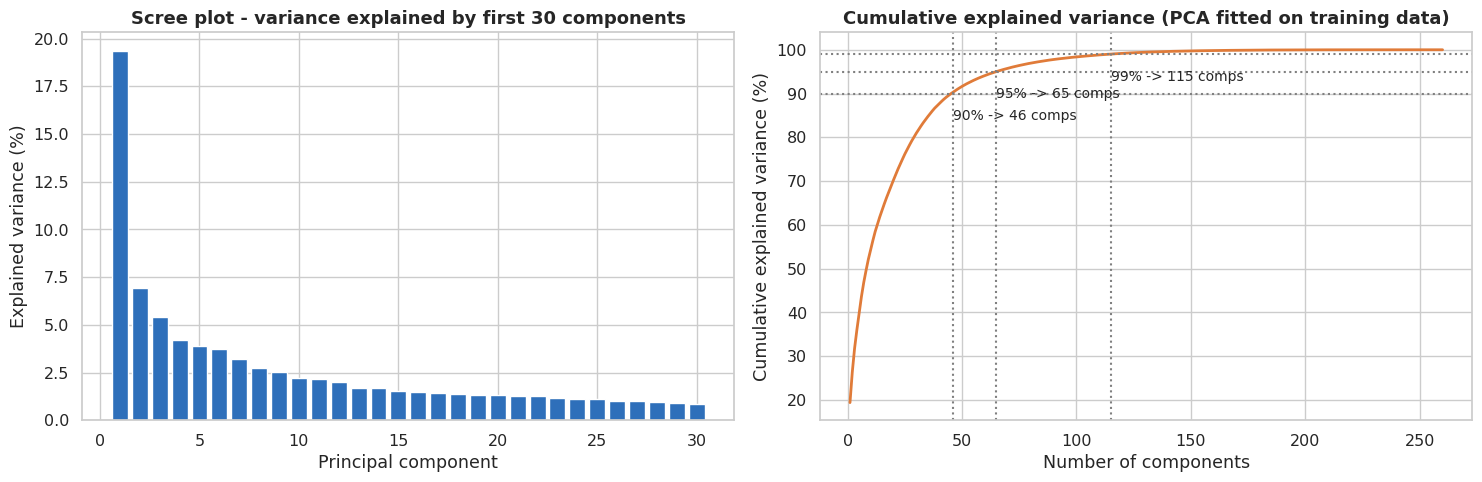

In [28]:
Ztr = build_encoder(scaled=True).fit_transform(prepare_df(X_train))
pca_full = PCA(random_state=RANDOM_STATE).fit(Ztr)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n90, n95, n99 = [int(np.argmax(cum >= p) + 1) for p in (.90, .95, .99)]
print(f"Encoded features: {Ztr.shape[1]} | components for 90% variance: {n90} | 95%: {n95} | 99%: {n99}")
print("PC1 explains", round(100 * pca_full.explained_variance_ratio_[0], 1), "% | first 5 PCs explain", round(100 * cum[4], 1), "%")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].bar(range(1, 31), pca_full.explained_variance_ratio_[:30] * 100, color="#2E6FBA")
ax[0].set_title("Scree plot - variance explained by first 30 components"); ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance (%)")
ax[1].plot(range(1, len(cum) + 1), cum * 100, color="#E07B39", lw=2)
for p, n in [(90, n90), (95, n95), (99, n99)]:
    ax[1].axhline(p, color="grey", ls=":"); ax[1].axvline(n, color="grey", ls=":"); ax[1].annotate(f"{p}% -> {n} comps", (n, p - 6), fontsize=10)
ax[1].set_title("Cumulative explained variance (PCA fitted on training data)"); ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative explained variance (%)")
save_fig("14_pca_explained_variance")
RES["pca_n"] = {"n90": n90, "n95": n95, "n99": n99, "pc1": float(pca_full.explained_variance_ratio_[0])}

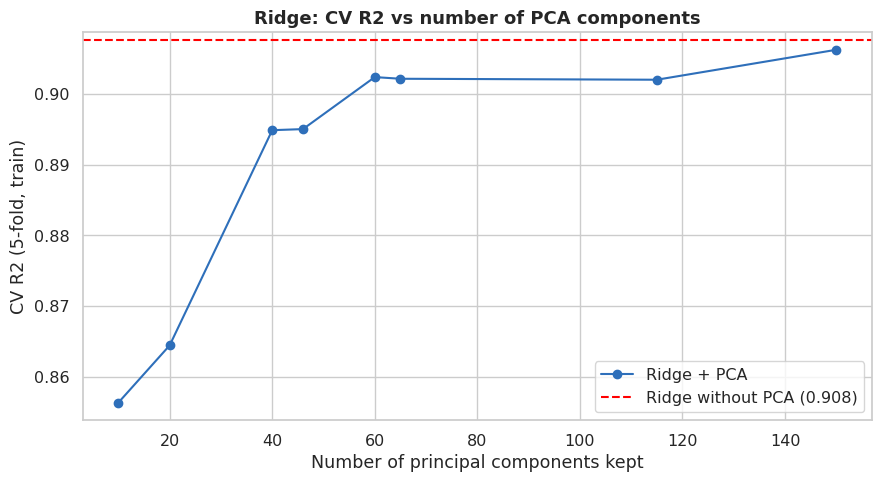

,Model,Components,CV R2 mean,CV R2 std
0,Ridge + PCA,10,0.8563,0.0188
1,Ridge + PCA,20,0.8644,0.0189
2,Ridge + PCA,40,0.8949,0.0192
3,Ridge + PCA,46,0.8950,0.0178
4,Ridge + PCA,60,0.9024,0.0180
5,Ridge + PCA,65,0.9021,0.0148
6,Ridge + PCA,115,0.9020,0.0186
7,Ridge + PCA,150,0.9062,0.0164


,Model,Input features,CV R2 mean,CV R2 std
0,Ridge,no PCA,0.9076,0.0167
1,Ridge,PCA (65 comps),0.9021,0.0148
2,Random Forest,no PCA,0.8848,0.0237
3,Random Forest,PCA (65 comps),0.8692,0.0372
4,Gradient Boosting,no PCA,0.9112,0.0230
5,Gradient Boosting,PCA (65 comps),0.8764,0.0216


In [29]:
# CV R2 of Ridge as we keep more principal components (PCA re-fitted inside every CV fold)
rows = []
for n in sorted(set([10, 20, 40, 60, n90, n95, 150, n99])):
    m, s = cv_r2(make_model(Ridge(alpha=10), scaled=True, pca=n))
    rows.append(["Ridge + PCA", n, m, s])
m0, s0 = cv_r2(make_model(Ridge(alpha=10), scaled=True))
pca_curve = pd.DataFrame(rows, columns=["Model", "Components", "CV R2 mean", "CV R2 std"])

plt.figure(figsize=(9, 5))
plt.plot(pca_curve.Components, pca_curve["CV R2 mean"], "o-", color="#2E6FBA", label="Ridge + PCA")
plt.axhline(m0, color="red", ls="--", label=f"Ridge without PCA ({m0:.3f})")
plt.title("Ridge: CV R2 vs number of PCA components"); plt.xlabel("Number of principal components kept"); plt.ylabel("CV R2 (5-fold, train)"); plt.legend()
save_fig("15_pca_vs_components")

# PCA with other model families, compared with their non-PCA versions
rows2 = [["Ridge", "no PCA", m0, s0]]
m, s = cv_r2(make_model(Ridge(alpha=10), scaled=True, pca=n95)); rows2.append(["Ridge", f"PCA ({n95} comps)", m, s])
m, s = cv_r2(make_model(RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1), scaled=False)); rows2.append(["Random Forest", "no PCA", m, s])
m, s = cv_r2(make_model(RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1), scaled=True, pca=n95)); rows2.append(["Random Forest", f"PCA ({n95} comps)", m, s])
m, s = cv_r2(make_model(GradientBoostingRegressor(random_state=RANDOM_STATE), scaled=False)); rows2.append(["Gradient Boosting", "no PCA", m, s])
m, s = cv_r2(make_model(GradientBoostingRegressor(random_state=RANDOM_STATE), scaled=True, pca=n95)); rows2.append(["Gradient Boosting", f"PCA ({n95} comps)", m, s])
pca_cmp = pd.DataFrame(rows2, columns=["Model", "Input features", "CV R2 mean", "CV R2 std"]).round(4)
display(pca_curve.round(4)); display(pca_cmp)
pca_cmp.to_csv("tables/pca_comparison.csv", index=False)
RES["pca_curve"] = pca_curve.round(4).to_dict("records"); RES["pca_compare"] = pca_cmp.to_dict("records")
save_table_image(pca_cmp, "shot_04_pca_comparison", "PCA experiment: with vs without PCA (5-fold CV R2 on train)", col_w=2.4)

**Findings:** The 261 encoded features can be compressed to 46 components for 90 % of the variance, 65 for 95 % and 115 for 99 %; the first component alone explains 19.4 %. **PCA did not improve any model**: Ridge 0.908 -> 0.902, Random Forest 0.885 -> 0.869, Gradient Boosting 0.911 -> 0.876 (CV R² with 65 components). Reasons: (1) PCA ignores the target, so components that capture variance are not necessarily the ones that explain price; (2) the one-hot columns of rare categories add variance but little predictive signal; (3) tree models work better on the original interpretable features; (4) regularised linear models already handle correlated features well. **Conclusion:** PCA was investigated as required, but the final model uses the original (encoded) features.

## 19. Baseline Models

A model is only useful if it beats a simple benchmark.

In [30]:
baseline_mean = DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_lin = make_model(LinearRegression(), scaled=True).fit(X_train, y_train)
rows = []
for n, m in [("Baseline: predict the mean price", baseline_mean), ("Baseline: Linear Regression", baseline_lin)]:
    r = evaluate(m, X_valid, y_valid); rows.append([n, r["R2"], r["MAE"], r["RMSE"]])
baseline_tbl = pd.DataFrame(rows, columns=["Model", "Valid R2", "Valid MAE", "Valid RMSE"]).round(4)
display(baseline_tbl); RES["baseline"] = baseline_tbl.to_dict("records")

,Model,Valid R2,Valid MAE,Valid RMSE
0,Baseline: predict the mean price,-0.0000,57131.8801,76375.9283
1,Baseline: Linear Regression,0.9341,14074.8902,19605.3878


## 20. Training and Comparing Multiple Models

Eight regression algorithms (all from scikit-learn) with sensible default settings. For each: 5-fold CV on the training part, then validation-set R², MAE, RMSE, and training R² (for the overfitting check).

*XGBoost, LightGBM, CatBoost and SHAP are not installed in this environment; `HistGradientBoostingRegressor` (a LightGBM-style boosting model) is used as the additional boosting algorithm and permutation importance replaces SHAP.*

In [31]:
models = {
    "Linear Regression": (LinearRegression(), True),
    "Ridge": (Ridge(alpha=10), True),
    "Lasso": (Lasso(alpha=0.001, max_iter=50000), True),
    "ElasticNet": (ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=50000), True),
    "Decision Tree": (DecisionTreeRegressor(random_state=RANDOM_STATE), False),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), False),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE), False),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=RANDOM_STATE), False),
}
rows, fitted = [], {}
for name, (est, scaled) in models.items():
    pipe = make_model(est, scaled=scaled)
    cm, cs = cv_r2(pipe)
    pipe.fit(X_train, y_train); fitted[name] = pipe
    v = evaluate(pipe, X_valid, y_valid); tr = evaluate(pipe, X_train, y_train)
    rows.append([name, tr["R2"], cm, cs, v["R2"], v["MAE"], v["RMSE"]])
    print(f"done: {name:22s} CV R2 = {cm:.4f}   Valid R2 = {v['R2']:.4f}")
comp = pd.DataFrame(rows, columns=["Model", "Train R2", "CV R2 mean", "CV R2 std", "Valid R2", "Valid MAE", "Valid RMSE"]).sort_values("Valid R2", ascending=False).round(4)
display(comp); comp.to_csv("tables/model_comparison_default.csv", index=False)
RES["model_comparison"] = comp.to_dict("records")

done: Linear Regression      CV R2 = 0.8988   Valid R2 = 0.9341


done: Ridge                  CV R2 = 0.9076   Valid R2 = 0.9450


done: Lasso                  CV R2 = 0.9098   Valid R2 = 0.9470


done: ElasticNet             CV R2 = 0.9099   Valid R2 = 0.9466


done: Decision Tree          CV R2 = 0.7519   Valid R2 = 0.7684


done: Random Forest          CV R2 = 0.8854   Valid R2 = 0.8856


done: Gradient Boosting      CV R2 = 0.9112   Valid R2 = 0.9117


done: HistGradientBoosting   CV R2 = 0.8794   Valid R2 = 0.8986


,Model,Train R2,CV R2 mean,CV R2 std,Valid R2,Valid MAE,Valid RMSE
2,Lasso,0.9355,0.9098,0.0143,0.9470,12711.9961,17589.9415
3,ElasticNet,0.9434,0.9099,0.0134,0.9466,12810.7808,17651.4171
1,Ridge,0.9470,0.9076,0.0167,0.9450,13043.5504,17908.6125
0,Linear Regression,0.9579,0.8988,0.0219,0.9341,14074.8902,19605.3878
6,Gradient Boosting,0.9733,0.9112,0.0230,0.9117,15465.3411,22696.3319
7,HistGradientBoosting,0.9870,0.8794,0.0314,0.8986,16384.5166,24318.4084
5,Random Forest,0.9846,0.8854,0.0229,0.8856,16334.9883,25829.8286
4,Decision Tree,1.0000,0.7519,0.0243,0.7684,24825.7182,36751.9195


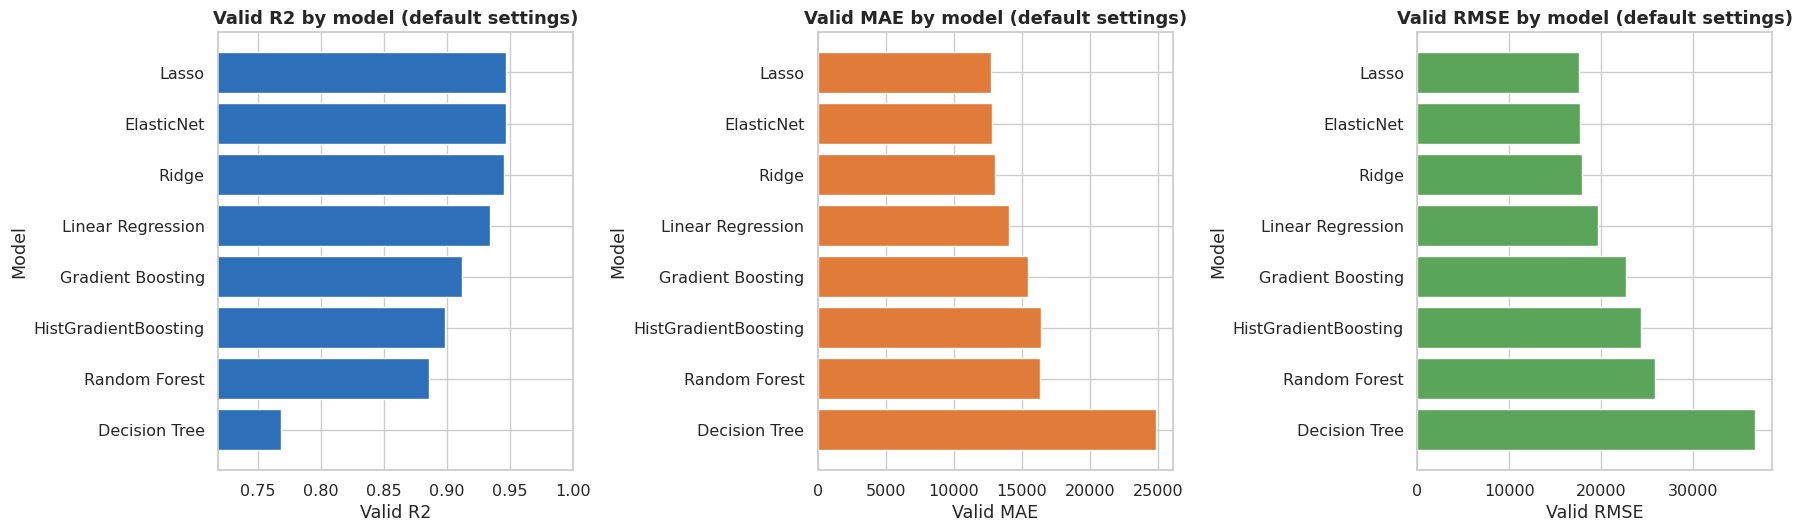

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
order = comp.sort_values("Valid R2").Model
for a, col, c in zip(ax, ["Valid R2", "Valid MAE", "Valid RMSE"], ["#2E6FBA", "#E07B39", "#5BA55B"]):
    d = comp.set_index("Model").loc[order, col]
    a.barh(d.index, d.values, color=c); a.set_title(f"{col} by model (default settings)"); a.set_xlabel(col); a.set_ylabel("Model")
    if col == "Valid R2": a.set_xlim(max(0, d.min() - .05), 1)
save_fig("16_model_comparison_default")
save_table_image(comp[["Model", "CV R2 mean", "Valid R2", "Valid MAE", "Valid RMSE"]], "shot_05_model_comparison", "Model comparison (default settings) - validation set", col_w=2.0)

**Insights:** The mean-price baseline gives R² = 0 (MAE $57,132), while plain Linear Regression already reaches validation R² 0.934 (MAE $14,075) - proving the features are very informative. The regularised linear models are the best: Lasso 0.947, ElasticNet 0.947, Ridge 0.945 (validation R²), followed by Gradient Boosting 0.912, HistGradientBoosting 0.899 and Random Forest 0.886. The unconstrained Decision Tree memorises the training data (train R² = 1.00 but validation 0.768). Boosting models have the best or similar cross-validation scores but a bigger gap between training and validation scores.

## 21. Hyper-parameter Tuning

`GridSearchCV` for small grids (Ridge, Lasso, Decision Tree) and `RandomizedSearchCV` for the larger searches (Random Forest, Gradient Boosting, HistGradientBoosting). All use **5-fold CV on the training part only** (no validation/test data), and the search sizes are kept modest.

In [33]:
P = "regressor__model__"
searches = {
 "Ridge": (make_model(Ridge(), scaled=True), {P+"alpha": [0.3, 1, 3, 10, 30, 100]}, "grid"),
 "Lasso": (make_model(Lasso(max_iter=50000), scaled=True), {P+"alpha": [0.0001, 0.0003, 0.001, 0.003, 0.01]}, "grid"),
 "Decision Tree": (make_model(DecisionTreeRegressor(random_state=RANDOM_STATE), scaled=False),
                   {P+"max_depth": [4, 6, 8, 10], P+"min_samples_leaf": [1, 5, 10, 20]}, "grid"),
 "Random Forest": (make_model(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), scaled=False),
                   {P+"n_estimators": [200, 400], P+"max_depth": [None, 12, 20], P+"min_samples_split": [2, 5, 10],
                    P+"min_samples_leaf": [1, 2, 4], P+"max_features": ["sqrt", 0.3, 0.5]}, 10),
 "Gradient Boosting": (make_model(GradientBoostingRegressor(random_state=RANDOM_STATE), scaled=False),
                   {P+"n_estimators": [300, 500, 800], P+"learning_rate": [0.02, 0.05, 0.1], P+"max_depth": [2, 3, 4],
                    P+"subsample": [0.7, 0.85, 1.0], P+"min_samples_leaf": [1, 3, 5, 10]}, 12),
 "HistGradientBoosting": (make_model(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scaled=False),
                   {P+"learning_rate": [0.03, 0.05, 0.1], P+"max_iter": [200, 400, 600], P+"max_leaf_nodes": [8, 15, 31],
                    P+"min_samples_leaf": [10, 20, 30], P+"l2_regularization": [0, 1, 10]}, 12),
}
tuned, rows = {}, []
for name, (pipe, grid, how) in searches.items():
    if how == "grid":
        gs = GridSearchCV(pipe, grid, cv=cv, scoring="r2", n_jobs=1)
    else:
        gs = RandomizedSearchCV(pipe, grid, n_iter=how, cv=cv, scoring="r2", random_state=RANDOM_STATE, n_jobs=1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    v = evaluate(gs.best_estimator_, X_valid, y_valid); tr = evaluate(gs.best_estimator_, X_train, y_train)
    bp = {k.replace(P, ""): v_ for k, v_ in gs.best_params_.items()}
    rows.append([name, bp, tr["R2"], gs.best_score_, gs.cv_results_["std_test_score"][gs.best_index_], v["R2"], v["MAE"], v["RMSE"]])
    print(f"tuned: {name:22s} best CV R2 = {gs.best_score_:.4f} | Valid R2 = {v['R2']:.4f} | {bp}")
tuned_tbl = pd.DataFrame(rows, columns=["Model", "Best parameters", "Train R2", "CV R2 mean", "CV R2 std", "Valid R2", "Valid MAE", "Valid RMSE"])
tuned_tbl["Selection score"] = ((tuned_tbl["CV R2 mean"] + tuned_tbl["Valid R2"]) / 2)
tuned_tbl = tuned_tbl.sort_values("Selection score", ascending=False).round(4).reset_index(drop=True)
display(tuned_tbl.drop(columns="Best parameters"))
tuned_tbl.to_csv("tables/model_comparison_tuned.csv", index=False)
RES["tuned"] = tuned_tbl.astype(object).to_dict("records")

tuned: Ridge                  best CV R2 = 0.9079 | Valid R2 = 0.9439 | {'alpha': 30}


tuned: Lasso                  best CV R2 = 0.9098 | Valid R2 = 0.9470 | {'alpha': 0.001}


tuned: Decision Tree          best CV R2 = 0.8022 | Valid R2 = 0.7846 | {'max_depth': 6, 'min_samples_leaf': 5}


tuned: Random Forest          best CV R2 = 0.8867 | Valid R2 = 0.9019 | {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20}


tuned: Gradient Boosting      best CV R2 = 0.9154 | Valid R2 = 0.9122 | {'subsample': 1.0, 'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 3, 'learning_rate': 0.05}


tuned: HistGradientBoosting   best CV R2 = 0.9071 | Valid R2 = 0.9155 | {'min_samples_leaf': 10, 'max_leaf_nodes': 8, 'max_iter': 600, 'learning_rate': 0.05, 'l2_regularization': 0}


,Model,Train R2,CV R2 mean,CV R2 std,Valid R2,Valid MAE,Valid RMSE,Selection score
0,Lasso,0.9355,0.9098,0.0143,0.9470,12711.9961,17589.9415,0.9284
1,Ridge,0.9407,0.9079,0.0159,0.9439,13085.2728,18084.9981,0.9259
2,Gradient Boosting,0.9782,0.9154,0.0234,0.9122,15514.0716,22635.0578,0.9138
3,HistGradientBoosting,0.9918,0.9071,0.0201,0.9155,15050.9748,22202.3056,0.9113
4,Random Forest,0.9847,0.8867,0.0220,0.9019,15375.2682,23921.6500,0.8943
5,Decision Tree,0.9109,0.8022,0.0418,0.7846,24256.2758,35448.6446,0.7934


In [34]:
for _, r in tuned_tbl.iterrows():
    print(f"{r.Model:22s} -> {r['Best parameters']}")
save_table_image(tuned_tbl[["Model", "Train R2", "CV R2 mean", "Valid R2", "Valid MAE", "Valid RMSE"]], "shot_06_tuned_models", "Tuned models - cross-validation and validation results", col_w=2.0)

Lasso                  -> {'alpha': 0.001}
Ridge                  -> {'alpha': 30}
Gradient Boosting      -> {'subsample': 1.0, 'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 3, 'learning_rate': 0.05}
HistGradientBoosting   -> {'min_samples_leaf': 10, 'max_leaf_nodes': 8, 'max_iter': 600, 'learning_rate': 0.05, 'l2_regularization': 0}
Random Forest          -> {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20}
Decision Tree          -> {'max_depth': 6, 'min_samples_leaf': 5}


## 22. Overfitting Check

Compare **training R²**, **cross-validation R²** and **validation R²**. A big gap between training and validation/CV means the model memorised the training data.

,Model,Train R2,CV R2 mean,Valid R2,Train - Valid gap
0,Lasso,0.9355,0.9098,0.9470,-0.0115
1,Ridge,0.9407,0.9079,0.9439,-0.0032
2,Gradient Boosting,0.9782,0.9154,0.9122,0.0660
3,HistGradientBoosting,0.9918,0.9071,0.9155,0.0763
4,Random Forest,0.9847,0.8867,0.9019,0.0828
5,Decision Tree,0.9109,0.8022,0.7846,0.1263


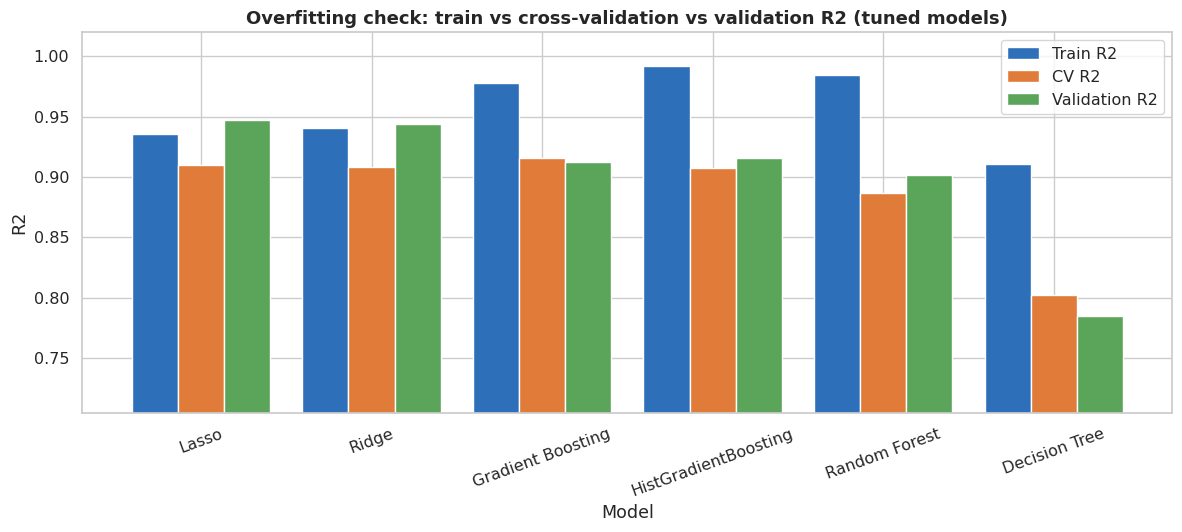

In [35]:
over = tuned_tbl[["Model", "Train R2", "CV R2 mean", "Valid R2"]].copy()
over["Train - Valid gap"] = (over["Train R2"] - over["Valid R2"]).round(4)
display(over)
RES["overfit"] = over.to_dict("records")

x = np.arange(len(over)); w = .27
plt.figure(figsize=(12, 5.5))
plt.bar(x - w, over["Train R2"], w, label="Train R2", color="#2E6FBA")
plt.bar(x, over["CV R2 mean"], w, label="CV R2", color="#E07B39")
plt.bar(x + w, over["Valid R2"], w, label="Validation R2", color="#5BA55B")
plt.xticks(x, over.Model, rotation=20); plt.ylim(max(0, min(over["CV R2 mean"].min(), over["Valid R2"].min()) - .08), 1.02)
plt.title("Overfitting check: train vs cross-validation vs validation R2 (tuned models)"); plt.ylabel("R2"); plt.xlabel("Model"); plt.legend()
save_fig("17_overfitting_check")

**Insights:** Linear models show **no overfitting** (train - validation gap about 0 or slightly negative: Lasso -0.012, Ridge -0.003). Boosting and Random Forest fit the training data much better than new data (gaps 0.066-0.083), and the Decision Tree has the largest gap (0.126). A high training score alone was therefore *not* used for selection.

## 23. Final Model Selection

Rule decided *before* looking at the test set: choose the tuned model with the highest **selection score = average of CV R² and validation R²** (so one lucky validation split cannot decide), while also checking MAE, RMSE, the train-validation gap, interpretability and run-time.

In [36]:
best_name = tuned_tbl.loc[0, "Model"]
best_est = tuned[best_name]
print("Selected final model:", best_name)
print("Best parameters     :", tuned_tbl.loc[0, "Best parameters"])
display(tuned_tbl.drop(columns=["Best parameters"]).head(3))
RES["best_name"] = best_name; RES["best_params"] = {k: (v if isinstance(v, (int, float, str, type(None))) else str(v)) for k, v in tuned_tbl.loc[0, "Best parameters"].items()}

Selected final model: Lasso
Best parameters     : {'alpha': 0.001}


,Model,Train R2,CV R2 mean,CV R2 std,Valid R2,Valid MAE,Valid RMSE,Selection score
0,Lasso,0.9355,0.9098,0.0143,0.9470,12711.9961,17589.9415,0.9284
1,Ridge,0.9407,0.9079,0.0159,0.9439,13085.2728,18084.9981,0.9259
2,Gradient Boosting,0.9782,0.9154,0.0234,0.9122,15514.0716,22635.0578,0.9138


**Selected model: Lasso regression (alpha = 0.001) on log-price with engineered features.** It has the highest selection score (0.928 = mean of CV R² 0.910 and validation R² 0.947), the lowest validation MAE ($12,712) and RMSE ($17,590), no overfitting, is fast and is easy to interpret. Gradient Boosting has the best CV R² (0.915) but a lower validation R² (0.912) and a larger overfitting gap, so the simpler model wins. Note that the top models are close, so differences of about 0.01 R² should not be over-interpreted.

## 24. Final Evaluation on the Hold-out Test Set

The chosen pipeline is **re-trained on train + validation** (more data) and evaluated **once** on the untouched 15 % test set.

In [37]:
final_eval_model = clone(best_est).fit(X_dev_fit, y_dev_fit)
pred_test = final_eval_model.predict(X_test)
mape = float(np.mean(np.abs((y_test - pred_test) / y_test)) * 100)
medape = float(np.median(np.abs((y_test - pred_test) / y_test)) * 100)
final_metrics = {"R2": r2_score(y_test, pred_test), "MAE": mean_absolute_error(y_test, pred_test),
                 "RMSE": root_mean_squared_error(y_test, pred_test), "MAPE %": mape, "Median abs % error": medape,
                 "R2 on log scale": r2_score(np.log1p(y_test), np.log1p(pred_test))}
fm = pd.Series(final_metrics).round(4).to_frame(f"{best_name} - hold-out test")
display(fm)
save_table_image(fm.reset_index().rename(columns={"index": "Metric"}), "shot_07_final_metrics", f"Final model ({best_name}) - hold-out test metrics", col_w=3.2)
RES["final_metrics"] = {k: float(v) for k, v in final_metrics.items()}
print(f"\nR2 = {final_metrics['R2']:.2%}  (project target: 75-85 %, above 85 % is better)")

,Lasso - hold-out test
R2,0.9321
MAE,13740.9123
RMSE,21672.9854
MAPE %,7.3746
Median abs % error,5.5295
R2 on log scale,0.9378



R2 = 93.21%  (project target: 75-85 %, above 85 % is better)


**Result on the untouched hold-out test set (219 properties):** R² = **0.932**, MAE = **$13,741**, RMSE = **$21,673**, mean absolute % error 7.4 % (median 5.5 %). 73 % of predictions are within 10 % of the real price and 94 % within 20 %. This is **above the 85 % 'much better' target** of the project. The test RMSE ($21.7k) is higher than the validation RMSE ($17.6k) because the test set contains a few very expensive houses that produce large dollar errors - a normal effect of splitting a small dataset.

## 25. Feature Importance / Interpretation

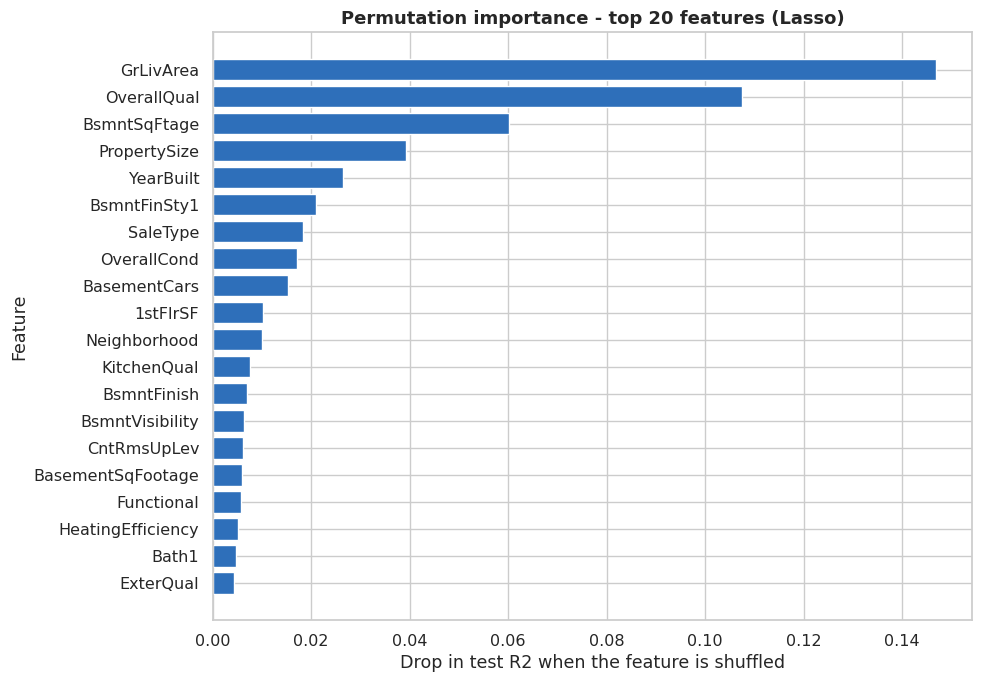

,importance
GrLivArea,0.1469
OverallQual,0.1075
BsmntSqFtage,0.0602
PropertySize,0.0392
YearBuilt,0.0265
BsmntFinSty1,0.0210
SaleType,0.0183
OverallCond,0.0172
BasementCars,0.0152
1stFlrSF,0.0103


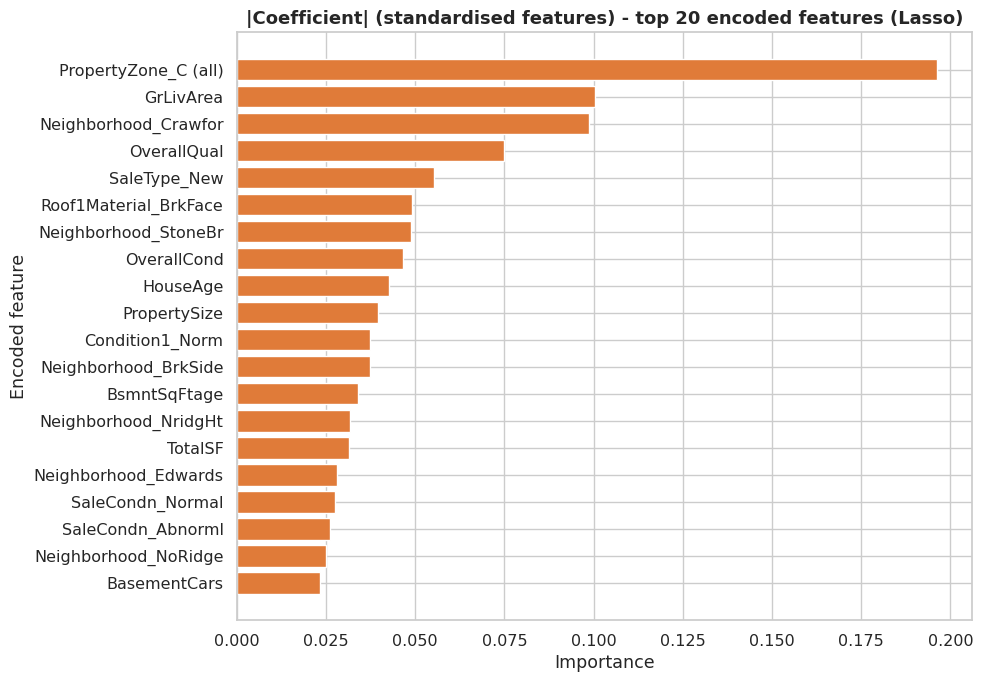

In [38]:
# (a) permutation importance on the ORIGINAL columns (works for any model; replaces SHAP here)
perm = permutation_importance(final_eval_model, X_test, y_test, scoring="r2", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
pi = pd.Series(perm.importances_mean, index=X_test.columns).drop(ID_COL).sort_values(ascending=False)
top_pi = pi.head(20)
plt.figure(figsize=(10, 7))
plt.barh(top_pi.index[::-1], top_pi.values[::-1], color="#2E6FBA")
plt.title(f"Permutation importance - top 20 features ({best_name})"); plt.xlabel("Drop in test R2 when the feature is shuffled"); plt.ylabel("Feature")
save_fig("18_permutation_importance")
RES["perm_importance"] = top_pi.round(4).to_dict()
display(top_pi.head(10).round(4).to_frame("importance"))

# (b) model's own importance (tree models) or |coefficients| (linear models) on encoded features
inner = final_eval_model.regressor_
feat_names = inner.named_steps["encode"].get_feature_names_out()
est = inner.named_steps["model"]
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=feat_names); label = "Built-in feature importance"
elif hasattr(est, "coef_"):
    imp = pd.Series(np.abs(est.coef_), index=feat_names); label = "|Coefficient| (standardised features)"
else:
    imp = None
if imp is not None:
    top_imp = imp.sort_values(ascending=False).head(20)
    plt.figure(figsize=(10, 7)); plt.barh(top_imp.index[::-1], top_imp.values[::-1], color="#E07B39")
    plt.title(f"{label} - top 20 encoded features ({best_name})"); plt.xlabel("Importance"); plt.ylabel("Encoded feature")
    save_fig("19_builtin_importance"); RES["builtin_importance"] = top_imp.round(4).to_dict()

**Insights:** Permutation importance (the drop in test R² when one original feature is shuffled) ranks **`GrLivArea` (0.147)** and **`OverallQual` (0.108)** far ahead of everything else, followed by total basement area `BsmntSqFtage` (0.060), lot size `PropertySize` (0.039), `YearBuilt` (0.027), finished basement area (0.021), `SaleType` (0.018), `OverallCond` (0.017) and garage capacity (0.015). `Neighborhood` and `KitchenQual` matter too (about 0.01 and 0.008). In simple words: **how big the house is and how good it is** drive the price, location and age come next. The second chart shows the absolute Lasso coefficients of the standardised encoded features; because one-hot columns of related categories share information, this view is less reliable than permutation importance and should be read with care (it is not causal either).

## 26. Actual vs Predicted

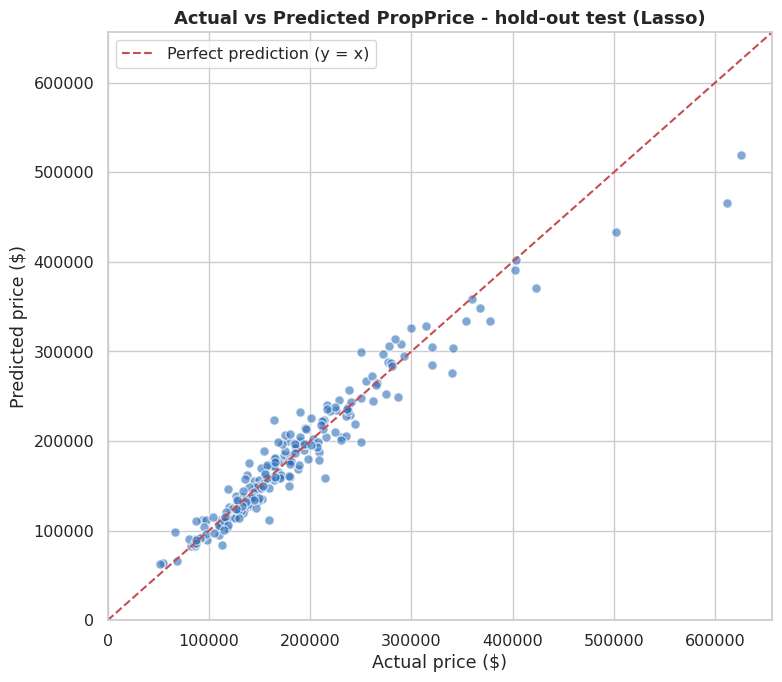

,Properties,MAE,Mean_residual,Mean_abs_pct_error
Price band,,,,
Q1 cheapest,55,7487.4,-389.9,7.6
Q2,55,9994.6,521.8,6.9
Q3,54,13494.5,-3925.6,7.4
Q4 most expensive,55,23982.6,11167.6,7.6


Within 10% of the real price: 73.1% | within 20%: 94.1% | under-predicted: 55.3%


In [39]:
res = pd.DataFrame({"Actual": y_test.values, "Predicted": pred_test}, index=y_test.index)
res["Residual"] = res.Actual - res.Predicted
res["Abs % error"] = (res.Residual.abs() / res.Actual * 100)

plt.figure(figsize=(8, 7))
plt.scatter(res.Actual, res.Predicted, alpha=.6, color="#2E6FBA", edgecolor="white", s=45)
lim = [0, max(res.Actual.max(), res.Predicted.max()) * 1.05]
plt.plot(lim, lim, "r--", label="Perfect prediction (y = x)"); plt.xlim(lim); plt.ylim(lim)
plt.title(f"Actual vs Predicted PropPrice - hold-out test ({best_name})"); plt.xlabel("Actual price ($)"); plt.ylabel("Predicted price ($)"); plt.legend()
save_fig("20_actual_vs_predicted")

res["Price band"] = pd.qcut(res.Actual, 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 most expensive"])
band = res.groupby("Price band", observed=True).agg(Properties=("Actual", "size"), MAE=("Residual", lambda s: s.abs().mean()),
                                                   Mean_residual=("Residual", "mean"), Mean_abs_pct_error=("Abs % error", "mean")).round(1)
display(band)
RES["band"] = band.reset_index().astype(object).to_dict("records")
RES["pct_under"] = float((res.Residual > 0).mean() * 100)
RES["within_10pct"] = float((res["Abs % error"] <= 10).mean() * 100); RES["within_20pct"] = float((res["Abs % error"] <= 20).mean() * 100)
print(f"Within 10% of the real price: {RES['within_10pct']:.1f}% | within 20%: {RES['within_20pct']:.1f}% | under-predicted: {RES['pct_under']:.1f}%")

In [ ]:
# Cross-check of the hold-out metrics with the zero-safe helper from property_utils.py.
# Percentage metrics skip rows whose true price is 0 (PropPrice has no zeros, so nothing is skipped here).
safe = regression_metrics(y_test, pred_test)
for k in ["R2", "MAE", "RMSE", "MAPE %", "Median abs % error"]:
    assert np.isclose(safe[k], final_metrics[k]), f"{k} differs: {safe[k]} vs {final_metrics[k]}"
assert np.isclose(safe["Within 10% of real price"], RES["within_10pct"])
assert np.isclose(safe["Within 20% of real price"], RES["within_20pct"])
print("Zero-target rows excluded:", safe["Zero-target rows excluded"])
display(pd.Series(safe).round(4).to_frame("zero-safe metrics (hold-out test)"))

**Insights:** Points follow the diagonal closely over the whole price range. Mean absolute % error is similar in every price quartile (6.9 %-7.6 %), but the dollar error grows with price (MAE $7,487 for the cheapest quarter vs $23,983 for the most expensive). The model tends to **under-predict expensive houses** (average residual +$11,168 in the top quarter), while 55 % of all houses are slightly under-predicted overall.

## 27. Residual Analysis

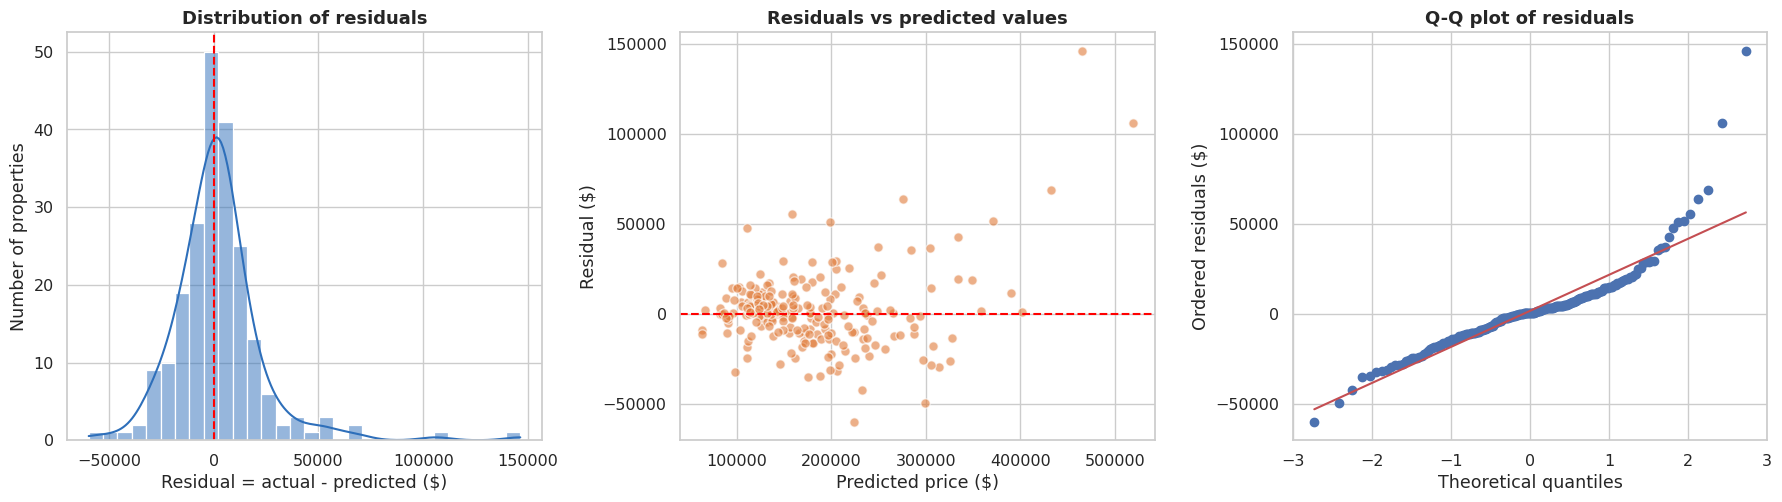

,value
mean residual,1869.80
median residual,699.26
std residual,21641.64
skewness,2.06
largest over-prediction ($),-59699.86
largest under-prediction ($),146338.94
"corr(|residual|, predicted)",0.52


In [40]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
sns.histplot(res.Residual, bins=30, kde=True, color="#2E6FBA", ax=ax[0]); ax[0].axvline(0, color="red", ls="--")
ax[0].set_title("Distribution of residuals"); ax[0].set_xlabel("Residual = actual - predicted ($)"); ax[0].set_ylabel("Number of properties")
ax[1].scatter(res.Predicted, res.Residual, alpha=.6, color="#E07B39", edgecolor="white", s=45); ax[1].axhline(0, color="red", ls="--")
ax[1].set_title("Residuals vs predicted values"); ax[1].set_xlabel("Predicted price ($)"); ax[1].set_ylabel("Residual ($)")
stats.probplot(res.Residual, dist="norm", plot=ax[2]); ax[2].set_title("Q-Q plot of residuals"); ax[2].set_xlabel("Theoretical quantiles"); ax[2].set_ylabel("Ordered residuals ($)")
save_fig("21_residual_analysis")
rs = {"mean residual": res.Residual.mean(), "median residual": res.Residual.median(), "std residual": res.Residual.std(), "skewness": res.Residual.skew(),
      "largest over-prediction ($)": res.Residual.min(), "largest under-prediction ($)": res.Residual.max(),
      "corr(|residual|, predicted)": np.corrcoef(res.Residual.abs(), res.Predicted)[0, 1]}
display(pd.Series(rs).round(2).to_frame("value")); RES["residual_stats"] = {k: float(v) for k, v in rs.items()}

**Insights:** Residuals are centred near zero (median +$699, mean +$1,870) but right-skewed (skewness 2.06) with a few large positive residuals - the largest under-prediction is $146,339 and the largest over-prediction $59,700. Residual size grows with the predicted price (correlation of |residual| with prediction = 0.52), i.e. errors in dollars are **heteroscedastic**, as expected for prices (a 7 % error on an expensive house is a larger dollar error); this is consistent with the roughly constant percentage error across price bands. The Q-Q plot shows heavier tails than a normal distribution. Model limitation: a linear model cannot fully capture the extra premium of very high-end houses.

## 28. Error Analysis

In [41]:
cols_show = ["PropertyID", "Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "SaleCondn"]
err = X_test[cols_show].join(res[["Actual", "Predicted", "Residual", "Abs % error"]])
top_abs = err.reindex(err.Residual.abs().sort_values(ascending=False).index).head(10)
top_pct = err.sort_values("Abs % error", ascending=False).head(10)
print("Top 10 largest absolute errors:"); display(top_abs.round(1))
print("Top 10 largest percentage errors:"); display(top_pct.round(1))
save_table_image(top_abs.round(0).reset_index(drop=True), "shot_08_error_analysis", "Ten largest prediction errors (hold-out test)", col_w=1.6, font=8)
RES["err_top_abs"] = top_abs.round(1).astype(object).to_dict("records")
RES["err_sale_cond_share"] = float((top_abs.SaleCondn != "Normal").mean() * 100)
print("Share of top-10 errors with a non-'Normal' sale condition:", RES["err_sale_cond_share"], "%  | share of non-Normal sales in the data:", round(100 * (df.SaleCondn != "Normal").mean(), 1), "%")

Top 10 largest absolute errors:


,PropertyID,Neighborhood,OverallQual,GrLivArea,YearBuilt,SaleCondn,Actual,Predicted,Residual,Abs % error
898,899,NridgHt,9,2364,2009,Partial,611657,465318.1,146338.9,23.9
1169,1170,NoRidge,10,3627,1995,Normal,625000,519068.2,105931.8,16.9
178,179,StoneBr,9,2234,2008,Partial,501837,432696.6,69140.4,13.8
377,378,Somerst,8,2466,2004,Normal,340000,275895.9,64104.1,18.9
1211,1212,Gilbert,8,1752,1988,Normal,164000,223699.9,-59699.9,36.4
328,329,BrkSide,6,2134,1916,Normal,214500,158704.9,55795.1,26.0
664,665,Somerst,8,2097,2005,Partial,423000,371160.0,51840.0,12.3
864,865,Somerst,7,1372,2007,Partial,250580,199285.8,51294.2,20.5
4,5,NoRidge,8,2198,2000,Normal,250000,299429.0,-49429.0,19.8
681,682,SWISU,5,1520,1932,Abnorml,159434,111415.7,48018.3,30.1


Top 10 largest percentage errors:


,PropertyID,Neighborhood,OverallQual,GrLivArea,YearBuilt,SaleCondn,Actual,Predicted,Residual,Abs % error
874,875,OldTown,5,1131,1941,Abnorml,66500,98478.0,-31978.0,48.1
1211,1212,Gilbert,8,1752,1988,Normal,164000,223699.9,-59699.9,36.4
681,682,SWISU,5,1520,1932,Abnorml,159434,111415.7,48018.3,30.1
1022,1023,OldTown,5,1248,1930,Normal,87000,111282.8,-24282.8,27.9
328,329,BrkSide,6,2134,1916,Normal,214500,158704.9,55795.1,26.0
1212,1213,Edwards,4,672,1941,Normal,113000,84464.1,28535.9,25.3
3,4,Crawfor,7,1717,1915,Abnorml,140000,175019.0,-35019.0,25.0
898,899,NridgHt,9,2364,2009,Partial,611657,465318.1,146338.9,23.9
330,331,NAmes,5,1728,1964,Normal,119000,146406.3,-27406.3,23.0
348,349,NridgHt,7,1626,2003,Normal,154000,188470.3,-34470.3,22.4


Share of top-10 errors with a non-'Normal' sale condition: 50.0 %  | share of non-Normal sales in the data: 17.9 %


**Insights:** The largest errors are almost all **expensive, high-quality houses that were under-predicted**: ID 899 (NridgHt, quality 9, `Partial` sale) sold for $611,657 but was predicted at $465,318; ID 1170 (NoRidge, quality 10) $625,000 vs $519,068; ID 179 (StoneBr, `Partial`) $501,837 vs $432,697. Half of the ten biggest errors have a non-`Normal` sale condition although only 17.9 % of all sales are non-normal - a `Partial`/abnormal sale can carry a price that the physical features cannot explain. ID 1212 (Gilbert, quality 8) is the largest over-prediction: $164,000 actual vs $223,700 predicted (36 % error); the data alone does not tell why, possibly an unrecorded problem with the house or a private sale. These are hypotheses, not proven causes.

## 29. Final Model Training, Saving and Prediction System

For deployment the selected pipeline is trained on **all labelled properties** (except the 2 non-representative Partial mega-house sales). (Its quality was already measured honestly on the hold-out test above - that number came from the model trained *without* the test rows.)

In [42]:
final_model = clone(best_est).fit(X_all_fit, y_all_fit)
joblib.dump(final_model, "property_price_model.pkl")
print("Saved: property_price_model.pkl")

# ---- how to load and use it later ----
loaded = joblib.load("property_price_model.pkl")

def predict_property_price(property_data, model=loaded):
    """property_data = dict (one property) or DataFrame (many properties).
    You may give only some fields - missing ones are treated as unknown/absent and handled by the pipeline."""
    out = model.predict(pd.DataFrame([property_data]) if isinstance(property_data, dict) else property_data)
    return float(out[0]) if isinstance(property_data, dict) else out

# Example 1: a full record taken from the hold-out test set
example = X_test.iloc[0].to_dict()
print("Example 1 (complete record)")
print("  Predicted price:", f"${predict_property_price(example):,.0f}", "| Actual price:", f"${y_test.iloc[0]:,.0f}")

# Example 2: a new property described with only the most important fields
new_house = {"OverallQual": 7, "GrLivArea": 1800, "BsmntSqFtage": 900, "1stFlrSF": 900, "2ndFlrSF": 900, "YearBuilt": 2005, "YearRemodAdd": 2005,
             "BasementCars": 2, "BasementSqFootage": 480, "Neighborhood": "CollgCr", "KitchenQual": "Gd", "ExterQual": "Gd",
             "Bath1": 2, "Bath2": 1, "BedroomUpLev": 3, "PropertySize": 9000, "SaleYr": 2010, "SaleMon": 6, "CentralAir": "Y", "CntRmsUpLev": 7}
print("Example 2 (partial record - 20 fields)")
print("  Predicted price:", f"${predict_property_price(new_house):,.0f}")
RES["example_pred_1"] = [float(predict_property_price(example)), float(y_test.iloc[0])]; RES["example_pred_2"] = float(predict_property_price(new_house))

Saved: property_price_model.pkl
Example 1 (complete record)
  Predicted price: $123,624 | Actual price: $127,000
Example 2 (partial record - 20 fields)
  Predicted price: $199,138


## 30. Test Predictions and `submission.csv`

> **Important:** `submission.csv` contains predictions for the **219 properties of the internal 15 % hold-out set**, made by the model that never saw them (trained on train + validation). It is **not** a prediction file for an official `test.csv` (none was supplied) and must not be presented as one. Format: `PropertyID, PropPrice` (`sample_submission.csv` was not supplied, so the usual convention is used).

When a real `test.csv` is available, create the final submission with the saved model:

```
python predict.py test.csv submission.csv --sample-submission sample_submission.csv
```

(`--sample-submission` is optional; it makes the output match that file's column names and row order exactly.)

In [43]:
submission = pd.DataFrame({"PropertyID": X_test[ID_COL].values, "PropPrice": pred_test.round(0).astype(int)}).sort_values("PropertyID")
submission.to_csv("submission.csv", index=False)
res_out = X_test[[ID_COL]].assign(Actual_PropPrice=y_test, Predicted_PropPrice=pred_test.round(0)).sort_values(ID_COL)
res_out.to_csv("test_predictions_vs_actual.csv", index=False)

# --- sanity checks ---
assert len(submission) == len(X_test), "wrong number of rows"
assert list(submission.columns) == ["PropertyID", "PropPrice"], "wrong columns"
assert submission.PropPrice.notna().all(), "missing predictions"
assert (submission.PropPrice > 0).all(), "impossible (non-positive) prices"
print("submission.csv OK ->", submission.shape, "| min =", submission.PropPrice.min(), "| max =", submission.PropPrice.max())
display(submission.head(8))
save_table_image(res_out.head(8).astype(int), "shot_09_predictions", "Sample test predictions (actual vs predicted)", col_w=2.4)

submission.csv OK -> (219, 2) | min = 62983 | max = 519068


,PropertyID,PropPrice
21,4,175019
51,5,299429
34,30,66151
181,32,136538
120,34,176450
11,51,179049
170,55,121571
162,57,196545


## 31. Results Summary and Project Checklist

In [44]:
json.dump(RES, open("results.json", "w"), indent=1, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
summary = pd.DataFrame({
    "Item": ["Properties / columns", "Best model", "Hold-out test R2", "MAE", "RMSE", "Median abs % error", "Within 10% of real price"],
    "Result": [f"{df.shape[0]} / {df.shape[1]}", best_name, f"{final_metrics['R2']:.4f}", f"${final_metrics['MAE']:,.0f}", f"${final_metrics['RMSE']:,.0f}",
               f"{final_metrics['Median abs % error']:.1f}%", f"{RES['within_10pct']:.1f}%"]})
display(summary)
checklist = pd.DataFrame({"Requirement": [
 "Data loaded, target & ID identified, duplicates & dtypes checked", "Missing values analysed and treated (fillna + imputers)",
 "Ordinal vs nominal identified (metadata)", "Ordinal encoding (explicit order) + One-Hot for nominal", "Scaling (inside pipeline) explained & used for linear models/PCA",
 "PCA experiment with explained variance and model comparison", "EDA: univariate, bivariate, correlation, outliers, insights", "Feature engineering + before/after comparison",
 "No data leakage (pipeline, CV on train only, test used once)", "Baseline + 8 models + cross-validation + hyper-parameter tuning",
 "R2, MAE, RMSE, overfitting check, residual & error analysis", "Feature importance", "Final model saved, prediction function, submission.csv"],
 "Done": ["Yes"] * 13})
display(checklist)

,Item,Result
0,Properties / columns,1460 / 81
1,Best model,Lasso
2,Hold-out test R2,0.9321
3,MAE,"$13,741"
4,RMSE,"$21,673"
5,Median abs % error,5.5%
6,Within 10% of real price,73.1%


,Requirement,Done
0,"Data loaded, target & ID identified, duplicate...",Yes
1,Missing values analysed and treated (fillna + ...,Yes
2,Ordinal vs nominal identified (metadata),Yes
3,Ordinal encoding (explicit order) + One-Hot fo...,Yes
4,Scaling (inside pipeline) explained & used for...,Yes
5,PCA experiment with explained variance and mod...,Yes
6,"EDA: univariate, bivariate, correlation, outli...",Yes
7,Feature engineering + before/after comparison,Yes
8,"No data leakage (pipeline, CV on train only, t...",Yes
9,Baseline + 8 models + cross-validation + hyper...,Yes


## 32. Conclusion

**Objective:** build a regression model that predicts `PropPrice` for 1,460 property sales described by 80 features.

**Data preparation:** only `PropertyID` was removed. NaN values that mean 'feature absent' were filled with an explicit `None` category using `fillna()`, real unknowns were imputed inside the pipeline, 22 ordinal columns were encoded with explicit order, 23 nominal columns were one-hot encoded, and numeric features were scaled for linear models. Two non-representative `Partial` mega-house sales were excluded from training only.

**EDA findings:** price is right-skewed (skew 1.88, 0.12 after log); `OverallQual` (r = 0.79) and `GrLivArea` (r = 0.71) are the strongest predictors; location matters (median $88k in MeadowV vs $315k in NridgHt).

**Experiments:** engineered features improved CV R² for every model; the log target helped; **PCA did not improve any model**, so it was not used in the final model.

**Best model:** Lasso regression (alpha 0.001). Hold-out test: **R² = 0.932, MAE = $13,741, RMSE = $21,673** (median error 5.5 %, 94 % of predictions within 20 %) - above the 85 % target. Most important features: living area, overall quality, basement area, lot size, year built.

**Limitations:** only 1,460 sales from one city, no real test file, expensive homes are under-predicted, sale conditions such as `Partial` add noise, and top models are close in score.

**Future work:** try XGBoost/LightGBM/CatBoost and SHAP, stacking/ensembling, interaction and neighbourhood-level features, a time-aware split, and prediction intervals.

## 33. References

1. Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python.* Journal of Machine Learning Research, 12, 2825-2830. https://scikit-learn.org
2. scikit-learn documentation - `Pipeline`, `ColumnTransformer`, `OrdinalEncoder`, `OneHotEncoder`, `SimpleImputer`, `PCA`, `RandomizedSearchCV`, `permutation_importance`. https://scikit-learn.org/stable/user_guide.html
3. pandas documentation. https://pandas.pydata.org/docs/
4. NumPy documentation. https://numpy.org/doc/
5. Matplotlib documentation. https://matplotlib.org/stable/ ; Seaborn documentation. https://seaborn.pydata.org/
6. De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project.* Journal of Statistics Education, 19(3). (original source of the data description, as stated in the project PDF)
7. Digicrome - *Capstone Project 1: Predicting Property Prices in a Specific Location Using Machine Learning* (project PDF and dataset provided to the student).
8. Geron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow* (3rd ed.), O'Reilly Media.